# IEEE-CIS Fraud Detection: Detaylı Keşifsel Veri Analizi

Bu notebook'ta veriyi hiç bilmiyormuş gibi ham dosyalardan başlayıp case'in Adım 1-3'te istediği analizleri ve sonraki adımlar (anomali katmanları, context kuralları, rule engine) için gereken keşifleri yapıyorum.

**Etiket kuralı:** `isFraud` birleştirmeden hemen sonra ayrı bir değişkene alınır ve yalnızca bölüm 17-18'de, yalnızca fit döneminde (ilk %80) kullanılır. Holdout'a etiketle bakılmaz.

**Grafikler:** plotly ile etkileşimli. Her grafiğin altında aynı bilginin sayısal tablosu da var.

| # | Bölüm | Case karşılığı |
|---|---|---|
| 1-3 | Kurulum, dosyalar, yükleme ve birleştirme | Adım 1: birleştirme |
| 4 | Otomatik kolon tipi çıkarımı | Adım 1: kolon tipleri, Adım 2: numeric/categorical/datetime |
| 5 | Veri kalitesi | Adım 1: veri kalite analizi |
| 6 | Eksik veri | Adım 1: eksik veri, Adım 2: null ratio |
| 7-8 | Zaman ofseti, başlangıç tarihi, fit/holdout | Adım 2: datetime |
| 9 | Dağılımlar ve zaman içinde kayma | Adım 1-2: distribution |
| 10 | Outlier analizi | Adım 2: outlier |
| 11 | Kardinalite ve nadir kategoriler | Adım 1: yüksek cardinality |
| 12 | Nadir kategorik kombinasyonlar | Adım 2: rare categorical combination |
| 13 | Kolon ilişkileri | Adım 2: kolon ilişkileri |
| 14 | Zaman desenleri | Adım 3 ve 6: temporal, iş saati, hafta sonu |
| 15 | Entity davranışı | Adım 2: entity davranış patternleri |
| 16 | Feature keşfi | Adım 3: temporal, entity, relational, context |
| 17 | Etiketli analiz (fit) | Adım 4-7 için tutarlılık kontrolü |
| 18 | Context ve kural adayları (fit) | Adım 6-7 |
| 19 | Sayısal özet | Paylaşım için |

## 1. Kurulum

In [1]:
import os
import gc
import time
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEED = 42
rng = np.random.default_rng(SEED)
pio.templates.default = "plotly_white"
C_MAIN, C_RISK, C_MUTED, C_ACCENT = "#2E5A88", "#C0392B", "#95A5A6", "#E67E22"

_kaggle = Path("/kaggle/input")
_found = sorted(_kaggle.glob("**/train_transaction.csv")) if _kaggle.exists() else []
DATA_DIR = _found[0].parent if _found else Path(os.environ.get("DATA_DIR", "data/raw"))
print("Veri klasörü:", DATA_DIR)

SUMMARY = {}          # paylaşım için anahtar sayılar (bölüm 19'da tablo olarak basılır)
T_START = time.time()


def note(key, value):
    """Anahtar bir sayıyı özet sözlüğüne yazar ve ekrana basar."""
    SUMMARY[key] = value
    print(f"{key}: {value}")


def show(fig, height=420):
    fig.update_layout(height=height, margin=dict(l=50, r=20, t=60, b=50))
    fig.show()


def hist_fig(values, bins=60, title="", xlabel="", log10_x=False, log_y=False, color=C_MAIN):
    """Histogramı önceden hesaplar (ham veriyi grafiğe gömmez, dosya küçük kalır)."""
    v = pd.Series(values).dropna().to_numpy(dtype="float64")
    if log10_x:
        v = np.log10(v[v > 0])
        xlabel = f"log10({xlabel})" if xlabel else "log10"
    cnt, edges = np.histogram(v, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    fig = go.Figure(go.Bar(x=centers, y=cnt, marker_color=color, width=np.diff(edges)))
    fig.update_layout(title=title, xaxis_title=xlabel, yaxis_title="adet", bargap=0)
    if log_y:
        fig.update_yaxes(type="log")
    return fig


def share_bar(s, top=15, title=""):
    vc = s.astype("object").fillna("(eksik)").value_counts(normalize=True).head(top)
    fig = go.Figure(go.Bar(x=vc.values[::-1], y=vc.index.astype(str)[::-1], orientation="h", marker_color=C_MAIN))
    fig.update_layout(title=title, xaxis_title="pay")
    return fig, vc


def col_group(c):
    """Kolonu adının önekine göre gruplar (V12 -> V, id_05 -> id, card3 -> card)."""
    c = c.replace("-", "_")
    for p in ["id_", "card", "addr", "dist", "V", "C", "D", "M"]:
        if c.startswith(p) and (p.endswith("_") or c[len(p):].isdigit()):
            return p.rstrip("_")
    return c if c in ("TransactionID", "TransactionDT", "isFraud") else "other"

Veri klasörü: /kaggle/input/competitions/ieee-fraud-detection


## 2. Dosyalar

Elimde hangi dosyalar var, ne büyüklükte, kaç satır ve kolon içeriyorlar? Train ve test dosyalarının kolonları aynı mı?

In [2]:
def count_rows(path):
    with open(path, "rb") as f:
        return sum(1 for _ in f) - 1

inv = []
for f in sorted(DATA_DIR.glob("*.csv")):
    cols = pd.read_csv(f, nrows=0).columns
    inv.append({"dosya": f.name, "boyut_MB": round(f.stat().st_size / 1e6, 1), "satır": count_rows(f),
                "kolon": len(cols), "ilk kolonlar": ", ".join(cols[:5])})
inv = pd.DataFrame(inv).set_index("dosya")
display(inv)

groups = {f: pd.Series([col_group(c) for c in pd.read_csv(DATA_DIR / f, nrows=0).columns]).value_counts()
          for f in inv.index}
display(pd.DataFrame(groups).fillna(0).astype(int))

def cols_of(name):
    p = DATA_DIR / name
    return set(pd.read_csv(p, nrows=0).columns) if p.exists() else set()

for a, b in [("train_transaction.csv", "test_transaction.csv"), ("train_identity.csv", "test_identity.csv")]:
    ca, cb = cols_of(a), cols_of(b)
    print(f"{a} vs {b}: yalnız train'de {sorted(ca - cb)[:6]} | yalnız test'te {sorted(cb - ca)[:6]}")

,boyut_MB,satır,kolon,ilk kolonlar
dosya,,,,
sample_submission.csv,6.1000,506691,2,"TransactionID, isFraud"
test_identity.csv,25.8000,141907,41,"TransactionID, id-01, id-02, id-03, id-04"
test_transaction.csv,613.2000,506691,393,"TransactionID, TransactionDT, TransactionAmt, ProductCD, card1"
train_identity.csv,26.5000,144233,41,"TransactionID, id_01, id_02, id_03, id_04"
train_transaction.csv,683.4000,590540,394,"TransactionID, isFraud, TransactionDT, TransactionAmt, ProductCD"


,sample_submission.csv,test_identity.csv,test_transaction.csv,train_identity.csv,train_transaction.csv
C,0,0,14,0,14
D,0,0,15,0,15
M,0,0,9,0,9
TransactionDT,0,0,1,0,1
TransactionID,1,1,1,1,1
V,0,0,339,0,339
addr,0,0,2,0,2
card,0,0,6,0,6
dist,0,0,2,0,2
id,0,38,0,38,0


train_transaction.csv vs test_transaction.csv: yalnız train'de ['isFraud'] | yalnız test'te []
train_identity.csv vs test_identity.csv: yalnız train'de ['id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06'] | yalnız test'te ['id-01', 'id-02', 'id-03', 'id-04', 'id-05', 'id-06']


## 3. Yükleme ve birleştirme

Bellek için sayısal kolonları küçültüyorum, düşük kardinaliteli metinleri `category` yapıyorum. Transaction ana tablo; identity'yi `TransactionID` üzerinden LEFT JOIN ile ekliyorum ki identity'si olmayan işlemler kaybolmasın.

In [3]:
def downcast(d):
    for c in d.columns:
        s = d[c]
        if pd.api.types.is_float_dtype(s):
            d[c] = s.astype("float32")
        elif pd.api.types.is_integer_dtype(s):
            d[c] = pd.to_numeric(s, downcast="integer")
        elif pd.api.types.is_string_dtype(s) and s.nunique(dropna=True) < 0.5 * len(s):
            d[c] = s.astype("category")
    return d

trans = downcast(pd.read_csv(DATA_DIR / "train_transaction.csv"))
ident = downcast(pd.read_csv(DATA_DIR / "train_identity.csv"))

In [4]:
trans.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5000,W,13926,NaN,150.0000,discover,142.0000,credit,315.0000,87.0000,19.0000,NaN,NaN,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,2.0000,0.0000,1.0000,1.0000,14.0000,NaN,13.0000,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,117.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,117.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0000,W,2755,404.0000,150.0000,mastercard,102.0000,credit,325.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0000,W,4663,490.0000,150.0000,visa,166.0000,debit,330.0000,87.0000,287.0000,NaN,outlook.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0000,W,18132,567.0000,150.0000,mastercard,117.0000,debit,476.0000,87.0000,NaN,NaN,yahoo.com,NaN,2.0000,5.0000,0.0000,0.0000,0.0000,4.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,25.0000,1.0000,112.0000,112.0000,0.0000,94.0000,0.0000,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,50.0000,"1,758.0000",925.0000,0.0000,354.0000,0.0000,135.0000,0.0000,0.0000,0.0000,50.0000,"1,404.0000",790.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0000,H,4497,514.0000,150.0000,mastercard,102.0000,credit,420.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [5]:
ident.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0000,"70,787.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0000,NotFound,NaN,-480.0000,New,NotFound,166.0000,NaN,542.0000,144.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0000,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0000,"98,945.0000",NaN,NaN,0.0000,-5.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,49.0000,-300.0000,New,NotFound,166.0000,NaN,621.0000,500.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,iOS 11.1.2,mobile safari 11.0,32.0000,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0000,"191,631.0000",0.0000,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,52.0000,NaN,Found,Found,121.0000,NaN,410.0000,142.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0000,"221,832.0000",NaN,NaN,0.0000,-6.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,52.0000,NaN,New,NotFound,225.0000,NaN,176.0000,507.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0000,"7,460.0000",0.0000,0.0000,1.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,NaN,-300.0000,Found,Found,166.0000,15.0000,529.0000,575.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,Mac OS X 10_11_6,chrome 62.0,24.0000,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [6]:
t0 = time.time()

print(f"okuma: {time.time() - t0:.0f} sn | transaction {trans.shape} | identity {ident.shape}")
print(f"bellek: transaction {trans.memory_usage(deep=True).sum() / 1e6:,.0f} MB | identity {ident.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
display(trans.head(10))
display(ident.head(10))

checks = {
    "transaction TransactionID tekil": trans["TransactionID"].is_unique,
    "identity TransactionID tekil": ident["TransactionID"].is_unique,
    "identity ID'lerinin hepsi transaction'da": ident["TransactionID"].isin(trans["TransactionID"]).all(),
}
test_dt = None
if (DATA_DIR / "test_transaction.csv").exists():
    test_dt = pd.read_csv(DATA_DIR / "test_transaction.csv", usecols=["TransactionID", "TransactionDT"])
    checks["train ve test ID'leri çakışmıyor"] = not trans["TransactionID"].isin(test_dt["TransactionID"]).any()
display(pd.Series(checks, name="sonuç").to_frame())

trans["has_identity"] = trans["TransactionID"].isin(ident["TransactionID"])
df = trans.merge(ident, on="TransactionID", how="left", validate="one_to_one")
del trans, ident; gc.collect()
note("satır", len(df))
note("kolon (birleşik)", df.shape[1])
note("identity payı", round(df["has_identity"].mean(), 4))
print("satır kaybı yok:", len(df) == SUMMARY["satır"], f"| bellek: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

okuma: 0 sn | transaction (590540, 394) | identity (144233, 41)
bellek: transaction 1,233 MB | identity 128 MB


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5000,W,13926,NaN,150.0000,discover,142.0000,credit,315.0000,87.0000,19.0000,NaN,NaN,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,2.0000,0.0000,1.0000,1.0000,14.0000,NaN,13.0000,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,117.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,117.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0000,W,2755,404.0000,150.0000,mastercard,102.0000,credit,325.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0000,W,4663,490.0000,150.0000,visa,166.0000,debit,330.0000,87.0000,287.0000,NaN,outlook.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0000,W,18132,567.0000,150.0000,mastercard,117.0000,debit,476.0000,87.0000,NaN,NaN,yahoo.com,NaN,2.0000,5.0000,0.0000,0.0000,0.0000,4.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,25.0000,1.0000,112.0000,112.0000,0.0000,94.0000,0.0000,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,50.0000,"1,758.0000",925.0000,0.0000,354.0000,0.0000,135.0000,0.0000,0.0000,0.0000,50.0000,"1,404.0000",790.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0000,H,4497,514.0000,150.0000,mastercard,102.0000,credit,420.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5,2987005,0,86510,49.0000,W,5937,555.0000,150.0000,visa,226.0000,debit,272.0000,87.0000,36.0000,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2987006,0,86522,159.0000,W,12308,360.0000,150.0000,visa,166.0000,debit,126.0000,87.0000,0.0000,NaN,yahoo.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2987007,0,86529,422.5000,W,12695,490.0000,150.0000,visa,226.0000,debit,325.0000,

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0000,"70,787.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0000,NotFound,NaN,-480.0000,New,NotFound,166.0000,NaN,542.0000,144.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0000,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0000,"98,945.0000",NaN,NaN,0.0000,-5.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,49.0000,-300.0000,New,NotFound,166.0000,NaN,621.0000,500.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,iOS 11.1.2,mobile safari 11.0,32.0000,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0000,"191,631.0000",0.0000,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,52.0000,NaN,Found,Found,121.0000,NaN,410.0000,142.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0000,"221,832.0000",NaN,NaN,0.0000,-6.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,52.0000,NaN,New,NotFound,225.0000,NaN,176.0000,507.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0000,"7,460.0000",0.0000,0.0000,1.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,NaN,-300.0000,Found,Found,166.0000,15.0000,529.0000,575.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,Mac OS X 10_11_6,chrome 62.0,24.0000,1280x800,match_status:2,T,F,T,T,desktop,MacOS
5,2987017,-5.0000,"61,141.0000",3.0000,0.0000,3.0000,0.0000,NaN,NaN,3.0000,0.0000,100.0000,NotFound,52.0000,-300.0000,Found,Found,166.0000,18.0000,529.0000,600.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,Windows 10,chrome 62.0,24.0000,1366x768,match_status:2,T,F,T,T,desktop,Windows
6,2987022,-15.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NotFound,14.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2987038,0.0000,"31,964.0000",0.0000,0.0000,0.0000,-10.0000,NaN,NaN,0.0000,0.0000,100.0000,Found,NaN,-300.0000,Found,Found,166.0000,15.0000,352.0000,533.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,Android,chrome 62.0,32.0000,1920x1080,match_status:2,T,F,T,T,mobile,NaN
8,2987040,-10.0000,"116,098.0000",0.0000,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,52.0000,NaN,Found,Found,121.0000,NaN,410.0000,142.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
9,2987048,-5.0000,"257,037.0000",NaN,NaN,0.0000,0.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,52.0000,NaN,New,NotFound,225.0000,NaN,484.0000,507.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows


,sonuç
transaction TransactionID tekil,True
identity TransactionID tekil,True
identity ID'lerinin hepsi transaction'da,True
train ve test ID'leri çakışmıyor,True


satır: 590540
kolon (birleşik): 435
identity payı: 0.2442
satır kaybı yok: True | bellek: 1.63 GB


## 4. Otomatik kolon tipi çıkarımı

Tipleri önce yalnızca veriye bakarak çıkarıyorum (değer tipi, farklı değer sayısı, tam sayı olup olmadığı, sıra numarasıyla ilişkisi). Sonra Vesta'nın "bu kolonlar kategoriktir" listesiyle karşılaştırıp veriden çıkarılamayan yerleri işaretliyorum.

Kurallar:
- metin: 2 farklı değer → `binary`, >1000 → `categorical_high`, diğer → `categorical`
- sayısal: ≤2 farklı değer → `binary`; `TransactionID` ile neredeyse tam sıralı ilişki → `datetime_offset`; tekil ve ardışık → `id`
- sayısal tam sayı: ≤50 farklı değer → `discrete`, daha fazlası → `integer`
- sayısal ondalıklı → `continuous`
- en sık değerin payı > %99 → ayrıca `quasi_constant` bayrağı

,kolon sayısı
çıkarılan_tip,
discrete,203
integer,110
continuous,80
binary,26
categorical,12
id,1
datetime_offset,1
target,1
categorical_high,1


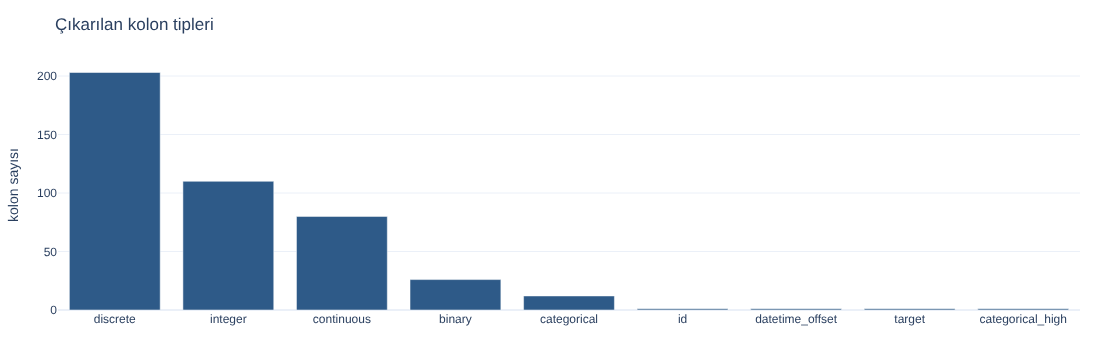

vesta_kategorik,Vesta: sayısal,Vesta: kategorik
çıkarılan_tip,,
binary,8,18
categorical,0,12
categorical_high,0,1
continuous,80,0
datetime_offset,1,0
discrete,198,5
id,1,0
integer,97,13
target,1,0


Veriden sayısal görünen ama Vesta'ya göre kategorik 18 kolon:


,çıkarılan_tip,farklı,eksik
kolon,,,
card1,integer,13553,0.0000
card2,integer,500,0.0151
card3,integer,114,0.0027
card5,integer,119,0.0072
addr1,integer,332,0.1113
addr2,integer,74,0.1113
id_13,integer,54,0.7844
id_14,discrete,25,0.8645
id_17,integer,104,0.7640


datetime_offset kolonları: TransactionDT
quasi_constant kolon sayısı: 24


In [7]:
VESTA_CATEGORICAL = (["ProductCD", "addr1", "addr2", "P_emaildomain", "R_emaildomain", "DeviceType", "DeviceInfo"]
                     + [f"card{i}" for i in range(1, 7)] + [f"M{i}" for i in range(1, 10)]
                     + [f"id_{i}" for i in range(12, 39)])

rid = df["TransactionID"].to_numpy()
sample_idx = rng.choice(len(df), size=min(200_000, len(df)), replace=False)

def infer_type(c):
    s = df[c]
    nun = s.nunique(dropna=True)
    if c == "isFraud":
        return "target"
    if not pd.api.types.is_numeric_dtype(s):
        return "binary" if nun == 2 else ("categorical_high" if nun > 1000 else "categorical")
    if nun <= 2:
        return "binary"
    if s.is_unique and s.notna().all() and (np.diff(np.sort(s.to_numpy())) == 1).all():
        return "id"
    if s.notna().all() and nun > 0.5 * len(s):
        r = pd.Series(s.to_numpy()[sample_idx]).corr(pd.Series(rid[sample_idx]), method="spearman")
        if r > 0.999:
            return "datetime_offset"
    v = s.dropna().to_numpy()[:200_000]
    if np.all(np.mod(v, 1) == 0):
        return "discrete" if nun <= 50 else "integer"
    return "continuous"

rows = []
for c in df.columns:
    s = df[c]
    top_share = s.value_counts(dropna=False, normalize=True).iloc[0]
    rows.append({"kolon": c, "grup": col_group(c), "dtype": str(s.dtype), "çıkarılan_tip": infer_type(c),
                 "vesta_kategorik": c in VESTA_CATEGORICAL, "farklı": s.nunique(dropna=True),
                 "eksik": s.isna().mean(), "en_sık_pay": top_share, "quasi_constant": top_share > 0.99})
types = pd.DataFrame(rows).set_index("kolon")

counts = types["çıkarılan_tip"].value_counts()
display(counts.to_frame("kolon sayısı"))
fig = go.Figure(go.Bar(x=counts.index, y=counts.values, marker_color=C_MAIN))
fig.update_layout(title="Çıkarılan kolon tipleri", yaxis_title="kolon sayısı")
show(fig, 360)

display(pd.crosstab(types["çıkarılan_tip"], types["vesta_kategorik"]).rename(columns={False: "Vesta: sayısal", True: "Vesta: kategorik"}))
mism = types[types["vesta_kategorik"] & ~types["çıkarılan_tip"].isin(["categorical", "categorical_high", "binary"])]
print(f"Veriden sayısal görünen ama Vesta'ya göre kategorik {len(mism)} kolon:")
display(mism[["çıkarılan_tip", "farklı", "eksik"]])
note("datetime_offset kolonları", ", ".join(types.index[types["çıkarılan_tip"] == "datetime_offset"]))
note("quasi_constant kolon sayısı", int(types["quasi_constant"].sum()))

## 5. Veri kalitesi

Kontroller: tekrarlı satırlar (ID hariç), içeriği birebir aynı kolonlar, sabit/neredeyse sabit kolonlar, beklenmeyen negatif ve sıfır değerler, kolonlar arası mantık tutarlılığı, train/test şema farkı.

In [8]:
def col_hash(s):
    return hashlib.md5(pd.util.hash_pandas_object(s, index=False).to_numpy().tobytes()).hexdigest()

row_h = pd.util.hash_pandas_object(df.drop(columns=["TransactionID"]), index=False)
dup_rows = int(row_h.duplicated().sum())

hashes = pd.Series({c: col_hash(df[c]) for c in df.columns if c != "TransactionID"})
dup_col_groups = hashes[hashes.duplicated(keep=False)].groupby(hashes).apply(lambda s: list(s.index))
dup_cols = int(sum(len(g) - 1 for g in dup_col_groups))

nonneg = ["TransactionAmt"] + [c for c in df.columns if col_group(c) in ("C", "D", "dist")]
neg = {c: int((df[c] < 0).sum()) for c in nonneg}
neg = {k: v for k, v in neg.items() if v > 0}

quality = pd.DataFrame([
    ("tekrarlı satır (ID hariç tüm kolonlar aynı)", dup_rows),
    ("içeriği birebir aynı kolon (fazlalık)", dup_cols),
    ("sabit kolon (tek değer)", int((types["farklı"] <= 1).sum())),
    ("neredeyse sabit kolon (en sık değer > %99)", int(types["quasi_constant"].sum())),
    ("TransactionAmt <= 0", int((df["TransactionAmt"] <= 0).sum())),
    ("negatif değerli C/D/dist kolonu", len(neg)),
    ("addr1 ve addr2 eksikliği uyumsuz satır", int((df["addr1"].isna() != df["addr2"].isna()).sum())),
    ("W ürününde identity olan işlem", int(((df["ProductCD"] == "W") & df["has_identity"]).sum())),
    ("D1 > 1000 gün (beklenmedik kart yaşı)", int((df["D1"] > 1000).sum())),
], columns=["kontrol", "adet"]).set_index("kontrol")
display(quality)
print("Negatif değer görülen kolonlar:", neg)
print(f"Birebir aynı kolon grupları (ilk 10 / toplam {len(dup_col_groups)}):")
for g in list(dup_col_groups)[:10]:
    print("  ", g)
qc = types.loc[types["quasi_constant"], ["en_sık_pay", "farklı", "eksik"]].sort_values("en_sık_pay", ascending=False)
print("Neredeyse sabit kolonlar:")
display(qc.head(20))
note("tekrarlı satır", dup_rows)
note("birebir aynı kolon", dup_cols)

,adet
kontrol,
tekrarlı satır (ID hariç tüm kolonlar aynı),3
içeriği birebir aynı kolon (fazlalık),0
sabit kolon (tek değer),0
neredeyse sabit kolon (en sık değer > %99),24
TransactionAmt <= 0,0
negatif değerli C/D/dist kolonu,6
addr1 ve addr2 eksikliği uyumsuz satır,0
W ürününde identity olan işlem,0
D1 > 1000 gün (beklenmedik kart yaşı),0


Negatif değer görülen kolonlar: {'D4': 15, 'D6': 3, 'D11': 7, 'D12': 2, 'D14': 3, 'D15': 15}
Birebir aynı kolon grupları (ilk 10 / toplam 0):
Neredeyse sabit kolonlar:


,en_sık_pay,farklı,eksik
kolon,,,
V305,1.0000,2,0.0000
V107,0.9990,2,0.0005
V117,0.9982,4,0.0005
V119,0.9982,4,0.0005
V118,0.9978,4,0.0005
V120,0.9978,4,0.0005
V122,0.9971,4,0.0005
V111,0.9965,10,0.0005
V113,0.9960,10,0.0005


tekrarlı satır: 3
birebir aynı kolon: 0


## 6. Eksik veri

Kolon ve grup bazında eksiklik, aynı satırlarda birlikte eksik olan kolon blokları, ürün tipine göre eksiklik (yapısal mı?) ve satır başına eksik kolon sayısı.

,mean,min,max,count
grup,,,,
id,0.8482,0.7558,0.9920,38
dist,0.7664,0.5965,0.9363,2
D,0.5815,0.0021,0.9341,15
M,0.4992,0.2868,0.5935,9
V,0.4304,0.0000,0.8612,339
other,0.3554,0.0000,0.7991,7
addr,0.1113,0.1113,0.1113,2
card,0.0051,0.0000,0.0151,6
C,0.0000,0.0000,0.0000,14


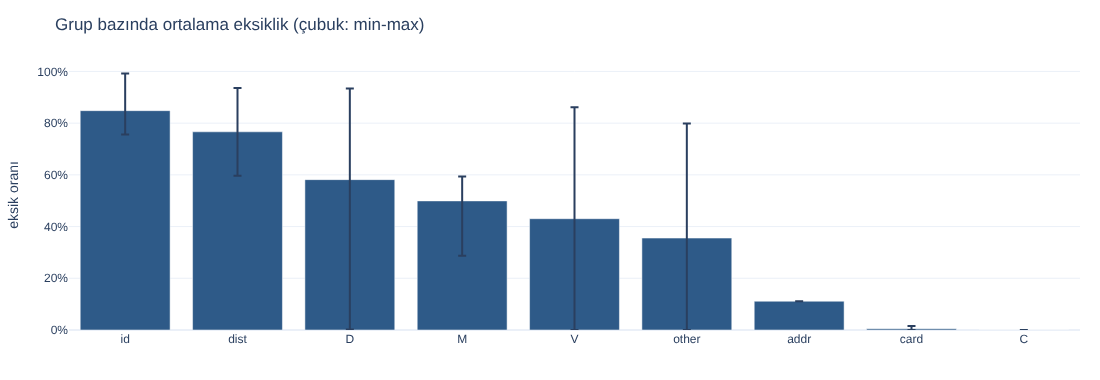

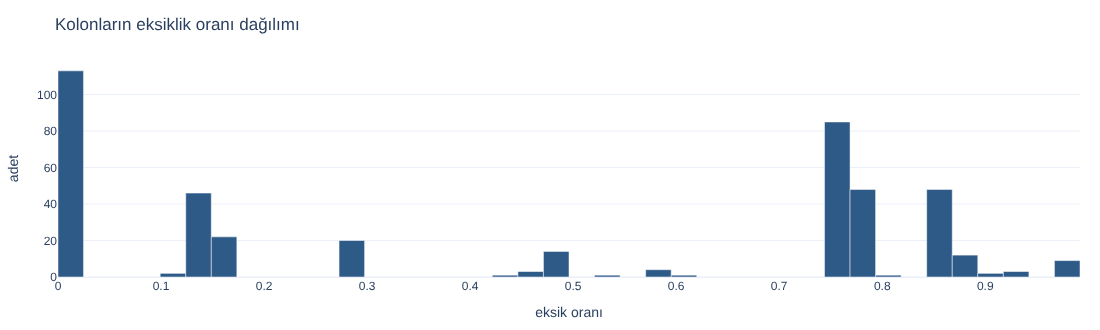

Eksik değeri olan 414 kolon, 69 farklı eksiklik deseninde toplanıyor.


,kolon_sayısı,null_ratio,gruplar,örnek
hash,,,,
01bc005d1ee9ad04ac4a7e3c02860fa0,46,0.7791,V,"V217, V218, V219, V223"
3b203235b54ad4460fffc1f7482f2189,43,0.0005,V,"V95, V96, V97, V98"
170443525c6e5822757bb7d0d6f26067,32,0.0000,V,"V279, V280, V284, V285"
06c053d92abfbbbba1ceb205e69bfb81,31,0.7636,V,"V167, V168, V172, V173"
8a2d27c7e3befe6239c53b18f606016c,23,0.1288,V,"V12, V13, V14, V15"
feefe761df2d18b898209386bf25b92c,22,0.1306,V,"V53, V54, V55, V56"
c429c1670448dcca5867b52433a9a7f1,20,0.1510,V,"V75, V76, V77, V78"
f5c1c3f5e27d0cc3591c1a1bc52b270e,19,0.7632,V,"V169, V170, V171, V174"
c0fa358d82189859c3d9e9caf9d4a4e1,18,0.8612,V,"V138, V139, V140, V141"


eksiklik bloğu sayısı: 69


In [9]:
null = df.isna().mean().rename("null_ratio").to_frame()
null["grup"] = [col_group(c) for c in null.index]
grp = (null.drop(index=[c for c in ("TransactionID", "TransactionDT", "isFraud") if c in null.index])
       .groupby("grup")["null_ratio"].agg(["mean", "min", "max", "count"]).sort_values("mean", ascending=False))
display(grp)

fig = go.Figure(go.Bar(x=grp.index, y=grp["mean"], marker_color=C_MAIN,
                       error_y=dict(type="data", symmetric=False, array=grp["max"] - grp["mean"], arrayminus=grp["mean"] - grp["min"])))
fig.update_layout(title="Grup bazında ortalama eksiklik (çubuk: min-max)", yaxis_title="eksik oranı", yaxis_tickformat=".0%")
show(fig, 380)

show(hist_fig(null["null_ratio"], bins=40, title="Kolonların eksiklik oranı dağılımı", xlabel="eksik oranı"), 330)

# Birlikte eksik olan bloklar: eksiklik maskesi birebir aynı olan kolonlar
mask_hash = pd.Series({c: hashlib.md5(np.packbits(df[c].isna().to_numpy()).tobytes()).hexdigest()
                       for c in df.columns if df[c].isna().any()})
blocks = (pd.DataFrame({"hash": mask_hash, "null_ratio": null.loc[mask_hash.index, "null_ratio"],
                        "grup": null.loc[mask_hash.index, "grup"]})
          .groupby("hash").agg(kolon_sayısı=("null_ratio", "size"), null_ratio=("null_ratio", "first"),
                               gruplar=("grup", lambda g: ",".join(sorted(set(g)))),
                               örnek=("null_ratio", lambda g: ", ".join(list(g.index[:4]))))
          .sort_values("kolon_sayısı", ascending=False))
print(f"Eksik değeri olan {len(mask_hash)} kolon, {len(blocks)} farklı eksiklik deseninde toplanıyor.")
display(blocks.head(15))
note("eksiklik bloğu sayısı", len(blocks))

,identity,R_emaildomain,addr,dist1,dist2,D (ort.),M (ort.),V (ort.)
ProductCD,,,,,,,,
C,0.0920,0.0310,0.9500,1.0000,0.6100,0.3470,0.8920,0.2410
H,0.0040,0.3280,0.0030,1.0000,0.9730,0.8370,1.0000,0.2690
R,0.0040,0.0000,0.0010,1.0000,0.8530,0.8090,1.0000,0.2680
S,0.0040,0.0510,0.0180,1.0000,0.6160,0.6480,1.0000,0.2360
W,1.0000,1.0000,0.0010,0.4580,1.0000,0.5780,0.3440,0.4910


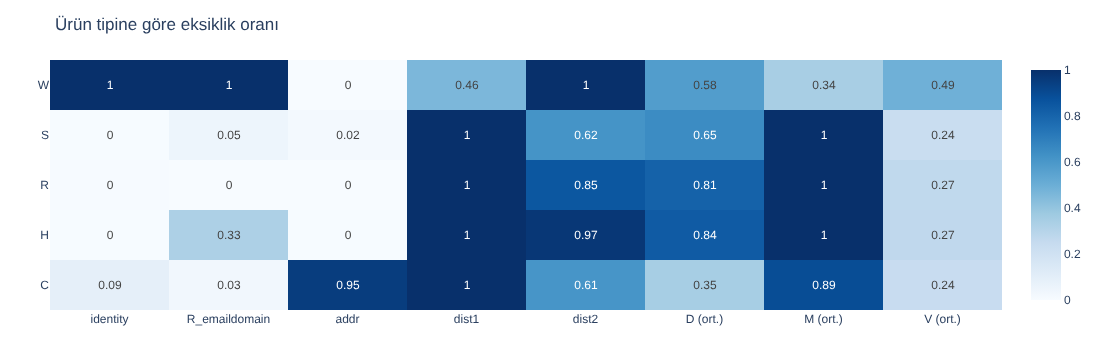

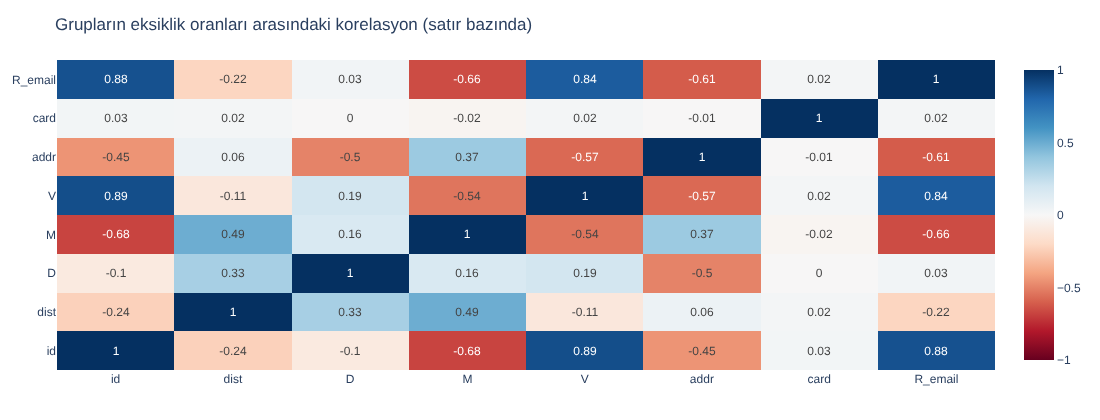

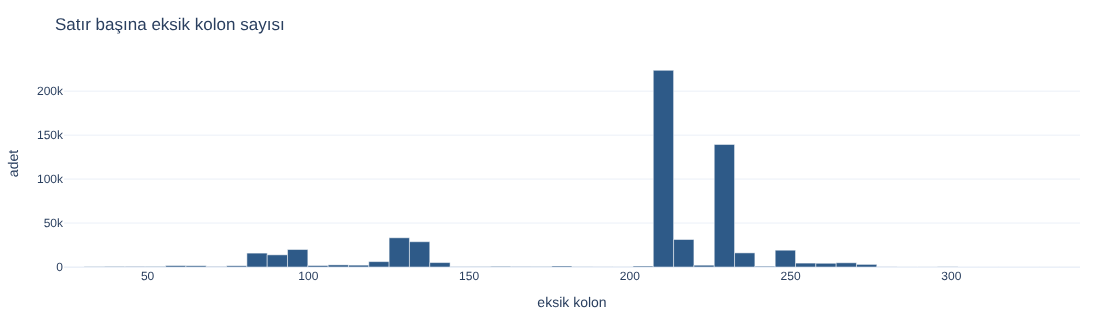

                          count     mean     std     min      10%      50%      90%      max
satır başına eksik 590,540.0000 195.6000 49.0000 24.0000 109.0000 211.0000 232.0000 340.0000


In [10]:
# Eksiklik yapısal mı? Ürün tipine göre grup eksikliği
heat_cols = {"identity": ~df["has_identity"], "R_emaildomain": df["R_emaildomain"].isna(),
             "addr": df["addr1"].isna(), "dist1": df["dist1"].isna(), "dist2": df["dist2"].isna(),
             "D (ort.)": df[[c for c in df.columns if col_group(c) == "D"]].isna().mean(axis=1),
             "M (ort.)": df[[c for c in df.columns if col_group(c) == "M"]].isna().mean(axis=1),
             "V (ort.)": df[[c for c in df.columns if col_group(c) == "V"]].isna().mean(axis=1)}
by_prod = pd.DataFrame({k: v.groupby(df["ProductCD"], observed=True).mean() for k, v in heat_cols.items()})
display(by_prod.round(3))
fig = go.Figure(go.Heatmap(z=by_prod.values, x=by_prod.columns, y=by_prod.index.astype(str), colorscale="Blues",
                           text=np.round(by_prod.values, 2), texttemplate="%{text}", zmin=0, zmax=1))
fig.update_layout(title="Ürün tipine göre eksiklik oranı")
show(fig, 360)

# Gruplar arası eksiklik ilişkisi
grp_null = pd.DataFrame({g: df[[c for c in df.columns if col_group(c) == g]].isna().mean(axis=1)
                         for g in ["id", "dist", "D", "M", "V", "addr", "card"]})
grp_null["R_email"] = df["R_emaildomain"].isna().astype(float)
cm = grp_null.corr()
fig = go.Figure(go.Heatmap(z=cm.values, x=cm.columns, y=cm.index, colorscale="RdBu", zmin=-1, zmax=1,
                           text=np.round(cm.values, 2), texttemplate="%{text}"))
fig.update_layout(title="Grupların eksiklik oranları arasındaki korelasyon (satır bazında)")
show(fig, 420)

row_nulls = df.isna().sum(axis=1)
show(hist_fig(row_nulls, bins=50, title="Satır başına eksik kolon sayısı", xlabel="eksik kolon"), 320)
print(row_nulls.describe(percentiles=[.1, .5, .9]).round(1).to_frame("satır başına eksik").T)

## 7. TransactionDT: birim ve başlangıç tarihi

Veride tarih kolonu yok. Transaction ve identity dosyalarındaki tek zaman bilgisi `TransactionDT`, ve bu bir tarih değil: Vesta'nın açıklamasına göre *"timedelta from a given reference datetime (not an actual timestamp)"*, yani bilinmeyen bir başlangıç anından itibaren geçen süre.

Bu bölümde üç soruyu veriyle cevaplıyorum:
1. Birim ne (saniye mi, dakika mı)?
2. Train ve test hangi aralığı kapsıyor, arada boşluk var mı?
3. Başlangıç tarihi veriden tahmin edilebilir mi?

,min,max,min → gün (saniye ise),max → gün (saniye ise),min → gün (dakika ise),max → gün (dakika ise)
train,86400,15811131,1.0000,182.9992,60.0000,"10,979.9521"
test,18403224,34214345,213.0003,395.9994,"12,780.0167","23,759.9618"


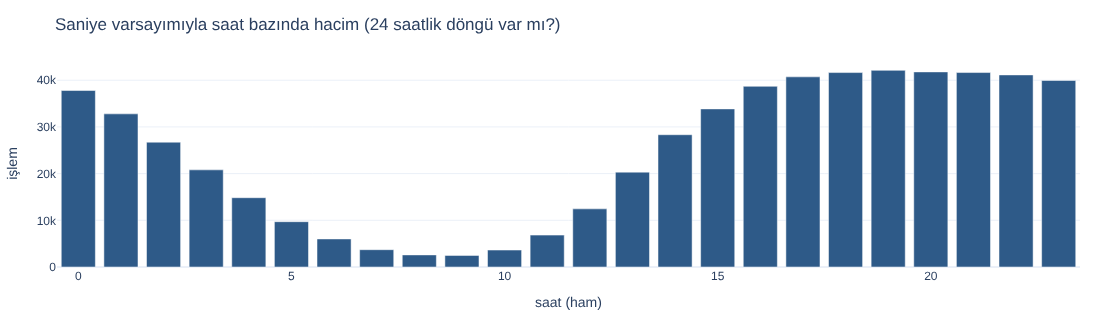

train-test arası boşluk (gün): 30.0


In [11]:
DAY = 86_400
dt_tr = df["TransactionDT"]
rng_tbl = {"train": dt_tr.agg(["min", "max"])}
if test_dt is not None:
    rng_tbl["test"] = test_dt["TransactionDT"].agg(["min", "max"])
rng_tbl = pd.DataFrame(rng_tbl).T
for unit, sec in [("gün (saniye ise)", DAY), ("gün (dakika ise)", 1_440)]:
    rng_tbl[f"min → {unit}"] = rng_tbl["min"] / sec
    rng_tbl[f"max → {unit}"] = rng_tbl["max"] / sec
display(rng_tbl)

hour_raw = (dt_tr // 3600) % 24
hc = hour_raw.value_counts().sort_index()
fig = go.Figure(go.Bar(x=hc.index, y=hc.values, marker_color=C_MAIN))
fig.update_layout(title="Saniye varsayımıyla saat bazında hacim (24 saatlik döngü var mı?)", xaxis_title="saat (ham)", yaxis_title="işlem")
show(fig, 320)
if test_dt is not None:
    note("train-test arası boşluk (gün)", round((test_dt["TransactionDT"].min() - dt_tr.max()) / DAY, 1))

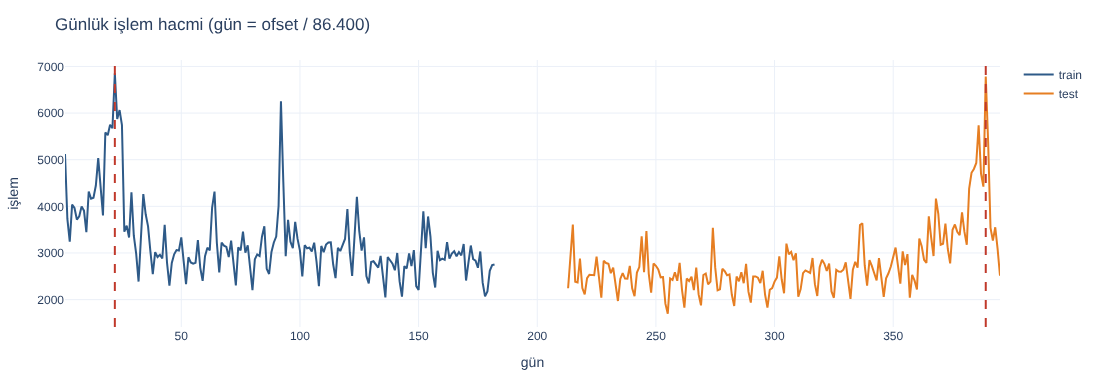

En yoğun 5 gün (train): [22, 92, 24, 23, 20]
En yoğun 5 gün (test): [389, 386, 390, 385, 384]
train ve test tepeleri arası gün: 367
referans tarih: 2017-12-01


In [12]:
daily_tr = (dt_tr // DAY).value_counts().sort_index()
fig = go.Figure(go.Scatter(x=daily_tr.index, y=daily_tr.values, mode="lines", name="train", line=dict(color=C_MAIN)))
peaks = {"train": int(daily_tr.idxmax())}
if test_dt is not None:
    daily_te = (test_dt["TransactionDT"] // DAY).value_counts().sort_index()
    fig.add_trace(go.Scatter(x=daily_te.index, y=daily_te.values, mode="lines", name="test", line=dict(color=C_ACCENT)))
    peaks["test"] = int(daily_te.idxmax())
for k, d in peaks.items():
    fig.add_vline(x=d, line_dash="dash", line_color=C_RISK)
fig.update_layout(title="Günlük işlem hacmi (gün = ofset / 86.400)", xaxis_title="gün", yaxis_title="işlem")
show(fig, 380)

print("En yoğun 5 gün (train):", daily_tr.nlargest(5).index.tolist())
if test_dt is not None:
    print("En yoğun 5 gün (test):", daily_te.nlargest(5).index.tolist())
    note("train ve test tepeleri arası gün", peaks["test"] - peaks["train"])

ASSUMED_PEAK = pd.Timestamp("2017-12-23")   # Noel öncesi en yoğun gün (varsayım)
REF_DATE = ASSUMED_PEAK - pd.Timedelta(days=peaks["train"])
REF_DATE = pd.Timestamp("2017-12-01") if abs((REF_DATE - pd.Timestamp("2017-12-01")).days) <= 1 else REF_DATE
note("referans tarih", str(REF_DATE.date()))

### Tarihi nasıl türettim ve ne kadar emin olabilirim?

**Birim:** Train'deki en küçük değer tam 86.400, yani bir gündeki saniye sayısı (24 × 60 × 60). Saniye kabul edilince düzgün bir 24 saatlik döngü çıkıyor. Dakika olsaydı train tek başına yaklaşık 30 yılı kapsardı. Birim saniye.

**Başlangıç tarihi:** Train ve test'te birer belirgin hacim tepesi var ve aralarında yaklaşık bir yıl (365 güne yakın) fark var; yani yılda bir tekrar eden bir olay. E-ticarette bunun en olası karşılığı Noel öncesi alışveriş (veri sağlayıcı ABD'li, tutarlar USD). Train tepesini 23 Aralık'a eşleyip geriye sayınca başlangıç 1 Aralık çıkıyor. Yıl veriden çıkarılamaz; yarışma 2019'da yapıldığı için 2017 varsaydım. Böylece **tarih = 2017-12-01 + TransactionDT (saniye)**.

| Bilgi | Kaynağı | Güven |
|---|---|---|
| Birim saniye | En küçük değer 86.400 ve 24 saatlik döngü | Yüksek |
| İşlem sırası, işlemler arası süre, velocity | `TransactionDT` farkları | Kesin; başlangıç tarihine bağlı değil |
| Ay ve gün (1 Aralık) | Yıllık tepe + Noel öncesi eşlemesi | Orta; makul bir çıkarım |
| Yıl (2017) | Yarışma tarihi | Varsayım |
| Saat | Saat ekseni kaymış görünüyor (bölüm 14) | "Gece" saatle değil, veriden (en düşük hacimli 6 saat) tanımlanıyor |
| Haftanın günü, hafta sonu, resmi tatiller | Başlangıç tarihine bağlı | Varsayıma bağlı |

**Bu varsayım sonuçları ne kadar etkiliyor?** Kritik feature'ların çoğu (velocity, önceki işlemden geçen süre, entity geçmişi) yalnızca zaman farklarını kullandığı için başlangıç tarihinden etkilenmiyor. Tarihe bağlı olanlar az: hafta sonu, resmi tatiller ve tatil sezonu. Tatil sezonunu da takvimden değil, veriden (hacim tepesinden) öğreniyorum (bölüm 14). Hafta sonu ve resmi tatil feature'larını varsayıma bağlı olarak işaretliyorum.

## 8. Fit / holdout ayrımı

Zamana göre sıralayıp ilk %80'i fit, son %20'yi holdout yapıyorum. Etiketi bu noktada veriden ayırıyorum.

,başlangıç,bitiş,satır
split,,,
fit,2017-12-02 00:00:00,2018-04-21 02:54:02,472432
holdout,2018-04-21 02:55:00,2018-06-01 23:58:51,118108


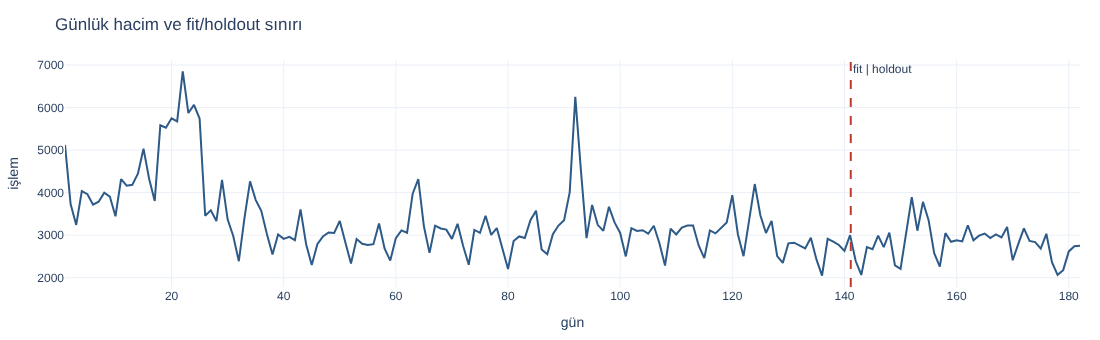

fit satır: 472432
holdout satır: 118108


In [13]:
FIT_RATIO = 0.8
df = df.sort_values(["TransactionDT", "TransactionID"]).reset_index(drop=True)
y = df.pop("isFraud")                       # etiket: yalnızca bölüm 17-18'de, yalnızca fit'te
df["dt"] = REF_DATE + pd.to_timedelta(df["TransactionDT"], unit="s")
df["day"] = (df["TransactionDT"] // DAY).astype("int32")
df["hour"] = df["dt"].dt.hour.astype("int8")
df["dow"] = df["dt"].dt.dayofweek.astype("int8")
n_fit = int(len(df) * FIT_RATIO)
fit = pd.Series(np.arange(len(df)) < n_fit, index=df.index)
df["split"] = np.where(fit, "fit", "holdout")

tbl = df.groupby("split").agg(başlangıç=("dt", "min"), bitiş=("dt", "max"), satır=("dt", "size"))
display(tbl)
dd = df.groupby("day").size()
split_day = df.loc[n_fit, "TransactionDT"] / DAY
fig = go.Figure(go.Scatter(x=dd.index, y=dd.values, mode="lines", line=dict(color=C_MAIN), name="günlük işlem"))
fig.add_vline(x=split_day, line_dash="dash", line_color=C_RISK, annotation_text="fit | holdout")
fig.update_layout(title="Günlük hacim ve fit/holdout sınırı", xaxis_title="gün", yaxis_title="işlem")
show(fig, 340)
note("fit satır", int(fit.sum()))
note("holdout satır", int((~fit).sum()))

## 9. Dağılımlar

Sayısal kolonların özeti (çarpıklık, basıklık), işlem tutarı, sık tekrarlanan tutarlar, kategorik dağılımlar ve fit ile holdout arasındaki kayma (PSI).

In [14]:
core_num = [c for c in df.columns if col_group(c) in ("C", "D", "dist") or c in ("TransactionAmt",)]
core_num += [c for c in df.columns if col_group(c) == "id" and pd.api.types.is_numeric_dtype(df[c])
             and types.loc[c, "çıkarılan_tip"] in ("continuous", "integer", "discrete") and int(c.split("_")[1]) <= 11]
desc = df[core_num].astype("float64").describe(percentiles=[.01, .5, .99]).T
desc["skew"] = df[core_num].astype("float64").skew()
desc["kurtosis"] = df[core_num].astype("float64").kurt()
display(desc.sort_values("skew", ascending=False).round(2))

v_cols = [c for c in df.columns if col_group(c) == "V"]
v_skew = df[v_cols].sample(min(100_000, len(df)), random_state=SEED).astype("float64").skew()
print(f"V kolonlarında çarpıklık: medyan {v_skew.median():.1f}, |skew| > 5 olan {int((v_skew.abs() > 5).sum())}/{len(v_cols)} kolon")

,count,mean,std,min,1%,50%,99%,max,skew,kurtosis
C3,"590,540.0000",0.0100,0.1500,0.0000,0.0000,0.0000,0.0000,26.0000,88.9500,"11,000.4400"
C12,"590,540.0000",4.0800,86.6700,0.0000,0.0000,0.0000,5.0000,"3,188.0000",27.4200,809.5900
C7,"590,540.0000",2.8500,61.7300,0.0000,0.0000,0.0000,4.0000,"2,255.0000",27.1900,794.0000
C8,"590,540.0000",5.1400,95.3800,0.0000,0.0000,0.0000,11.0000,"3,331.0000",26.0800,742.4100
C10,"590,540.0000",5.2400,95.5800,0.0000,0.0000,0.0000,15.0000,"3,257.0000",25.2200,689.5900
C1,"590,540.0000",14.0900,133.5700,0.0000,1.0000,1.0000,164.0000,"4,685.0000",23.9600,669.3800
C2,"590,540.0000",15.2700,154.6700,0.0000,1.0000,1.0000,154.0000,"5,691.0000",23.6800,655.1700
C11,"590,540.0000",10.2400,94.3400,0.0000,1.0000,1.0000,122.0000,"3,188.0000",22.3600,583.1200
C4,"590,540.0000",4.0900,68.8500,0.0000,0.0000,0.0000,6.0000,"2,253.0000",22.0800,543.4100
C6,"590,540.0000",9.0700,71.5100,0.0000,0.0000,1.0000,118.0000,"2,253.0000",19.7700,463.8300


V kolonlarında çarpıklık: medyan 12.0, |skew| > 5 olan 250/339 kolon


,count,mean,std,min,1%,10%,25%,50%,75%,90%,99%,99.9%,max
TransactionAmt,"590,540.0000",135.0272,239.1625,0.2510,9.2440,25.9500,43.3210,68.7690,125.0000,275.2930,"1,104.0000","2,769.8073","31,937.3906"


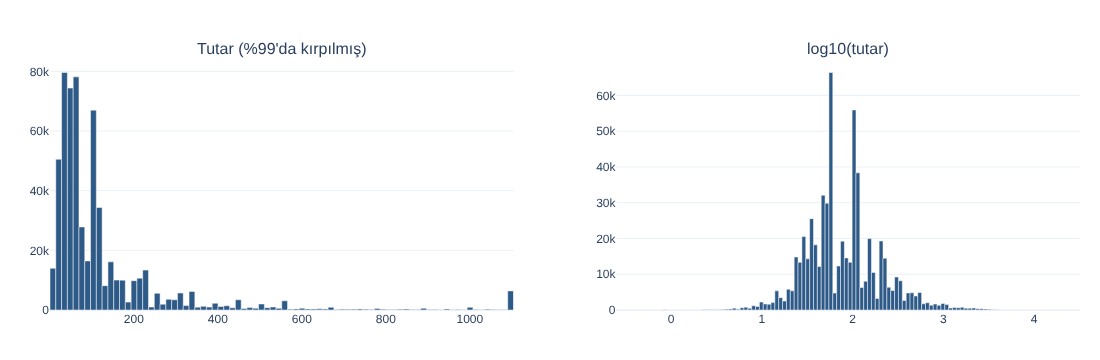

,pay,adet
TransactionAmt,,
59.0000,0.0518,30582
117.0000,0.0490,28933
107.9500,0.0406,23954
57.9500,0.0400,23600
100.0000,0.0345,20362
50.0000,0.0288,17009
49.0000,0.0271,15990
226.0000,0.0198,11704
39.0000,0.0188,11095


addr1,addr1 dolu,addr1 boş
amt_decimals,,
0,0.9980,0.0020
1,0.9790,0.0210
2,0.9710,0.0290
3,0.0490,0.9510


3 ondalıklı tutar payı: 0.1049
en sık 15 tutarın toplam payı: 0.3999


,0.0500,0.2500,0.5000,0.7500,0.9500
ProductCD,,,,,
C,7.7500,18.4200,31.1900,54.1000,119.6300
H,25.0000,35.0000,50.0000,100.0000,200.0000
R,50.0000,100.0000,125.0000,200.0000,400.0000
S,10.0000,20.0000,35.0000,80.0000,150.0000
W,26.9500,49.0000,78.5000,146.0000,500.0000


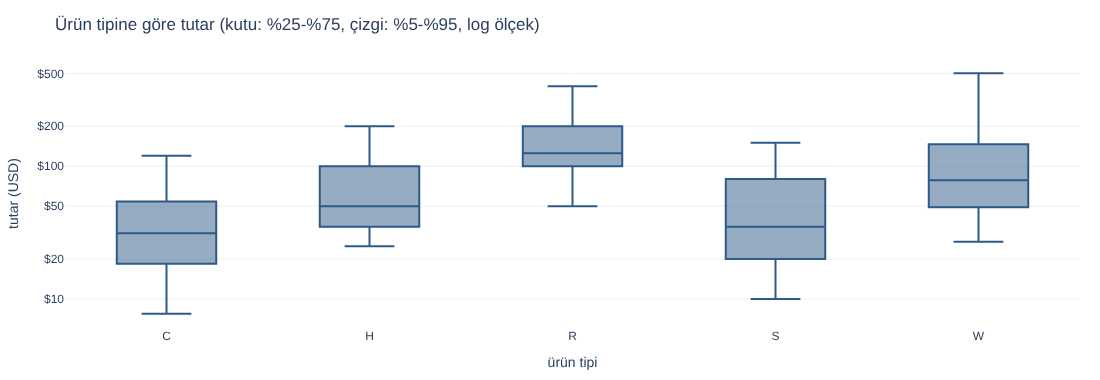

In [15]:
amt = df["TransactionAmt"].astype("float64")
display(amt.describe(percentiles=[.01, .1, .25, .5, .75, .9, .99, .999]).to_frame().T)
fig = make_subplots(rows=1, cols=2, subplot_titles=("Tutar (%99'da kırpılmış)", "log10(tutar)"))
for i, (vals, b) in enumerate([(amt.clip(upper=amt.quantile(.99)), 80), (np.log10(amt[amt > 0]), 120)], start=1):
    cnt, edges = np.histogram(vals, bins=b)
    fig.add_trace(go.Bar(x=(edges[:-1] + edges[1:]) / 2, y=cnt, width=np.diff(edges), marker_color=C_MAIN, showlegend=False), 1, i)
fig.update_layout(bargap=0)
show(fig, 360)

top_amt = amt.round(3).value_counts().head(15)
display((top_amt / len(df)).rename("pay").to_frame().assign(adet=top_amt))
dec = amt.round(3).map(lambda v: 0 if v == int(v) else len(f"{v:.3f}".rstrip("0").split(".")[1]))
df["amt_decimals"] = dec.astype("int8")
display(pd.crosstab(df["amt_decimals"], df["addr1"].isna(), normalize="index").round(3).rename(columns={False: "addr1 dolu", True: "addr1 boş"}))
note("3 ondalıklı tutar payı", round((df["amt_decimals"] == 3).mean(), 4))
note("en sık 15 tutarın toplam payı", round(top_amt.sum() / len(df), 4))

q = amt.groupby(df["ProductCD"], observed=True).quantile([.05, .25, .5, .75, .95]).unstack()
display(q.round(2))
fig = go.Figure()
for p in q.index:
    fig.add_trace(go.Box(name=str(p), x=[str(p)], q1=[q.loc[p, .25]], median=[q.loc[p, .5]], q3=[q.loc[p, .75]],
                         lowerfence=[q.loc[p, .05]], upperfence=[q.loc[p, .95]], marker_color=C_MAIN))
    
ticks = [5, 10, 20, 50, 100, 200, 500]
fig.update_layout(title="Ürün tipine göre tutar (kutu: %25-%75, çizgi: %5-%95, log ölçek)",
                  yaxis=dict(type="log", title="tutar (USD)", tickvals=ticks, ticktext=[f"${t}" for t in ticks]),
                  xaxis_title="ürün tipi", showlegend=False)
show(fig, 380)

baskın addr2 değeri: 87.0


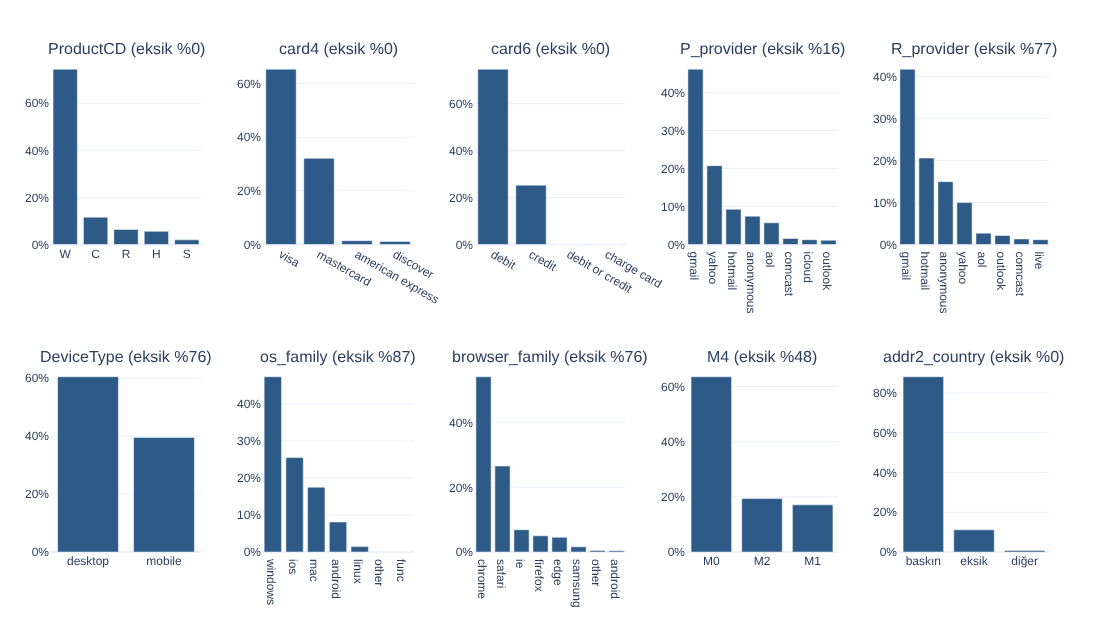

ProductCD: W=0.745, C=0.116, R=0.064, H=0.056, S=0.02
card4: visa=0.652, mastercard=0.32, american express=0.014, discover=0.011, (eksik)=0.003
card6: debit=0.745, credit=0.252, (eksik)=0.003, debit or credit=0.0, charge card=0.0
P_provider: gmail=0.388, yahoo=0.174, (eksik)=0.16, hotmail=0.078, anonymous=0.063
R_provider: (eksik)=0.768, gmail=0.097, hotmail=0.048, anonymous=0.035, yahoo=0.023
DeviceType: (eksik)=0.762, desktop=0.144, mobile=0.094
os_family: (eksik)=0.869, windows=0.062, ios=0.033, mac=0.023, android=0.011
browser_family: (eksik)=0.762, chrome=0.129, safari=0.063, ie=0.016, firefox=0.012
M4: (eksik)=0.477, M0=0.333, M2=0.101, M1=0.089
addr2_country: baskın=0.881, eksik=0.111, diğer=0.007


In [16]:
def fam(s, n=1):
    """'Windows 10' -> 'Windows', 'chrome 63.0' -> 'chrome', 'gmail.com' -> 'gmail'."""
    return s.astype("object").map(lambda v: v if pd.isna(v) else str(v).replace(".", " ").split(" ")[0].lower())

df["os_family"] = fam(df["id_30"]) if "id_30" in df else np.nan
def browser_family(s):
    def f(v):
        if pd.isna(v):
            return v
        v = str(v).lower()
        for key, name in [("safari", "safari"), ("chrome", "chrome"), ("firefox", "firefox"), ("edge", "edge"),
                          ("ie ", "ie"), ("samsung", "samsung"), ("opera", "opera"), ("android", "android")]:
            if key in v:
                return name
        return "other"
    return s.astype("object").map(f)

df["browser_family"] = browser_family(df["id_31"]) if "id_31" in df else np.nan
df["P_provider"] = fam(df["P_emaildomain"])
df["R_provider"] = fam(df["R_emaildomain"])
dom_addr2 = df.loc[fit, "addr2"].mode()[0]
df["addr2_country"] = np.where(df["addr2"].isna(), "eksik", np.where(df["addr2"] == dom_addr2, "baskın", "diğer"))
note("baskın addr2 değeri", float(dom_addr2))

cat_show = ["ProductCD", "card4", "card6", "P_provider", "R_provider", "DeviceType", "os_family", "browser_family", "M4", "addr2_country"]
titles = [f"{c} (eksik %{df[c].isna().mean() * 100:.0f})" for c in cat_show]
fig = make_subplots(rows=2, cols=5, subplot_titles=titles, horizontal_spacing=0.06)
for i, c in enumerate(cat_show):
    vc = df[c].dropna().astype("object").value_counts(normalize=True).head(8)
    fig.add_trace(go.Bar(x=vc.index.astype(str), y=vc.values, marker_color=C_MAIN, showlegend=False), i // 5 + 1, i % 5 + 1)
fig.update_yaxes(tickformat=".0%")
show(fig, 620)
for c in cat_show:
    vc = df[c].astype("object").fillna("(eksik)").value_counts(normalize=True).head(5).round(3)
    print(f"{c}: " + ", ".join(f"{k}={v}" for k, v in vc.items()))

,PSI (fit → holdout)
D15,0.0838
D10,0.0586
ProductCD,0.0502
D4,0.0335
browser_family,0.0283
D1,0.0243
C13,0.0191
os_family,0.0188
DeviceType,0.0166
has_identity,0.0165


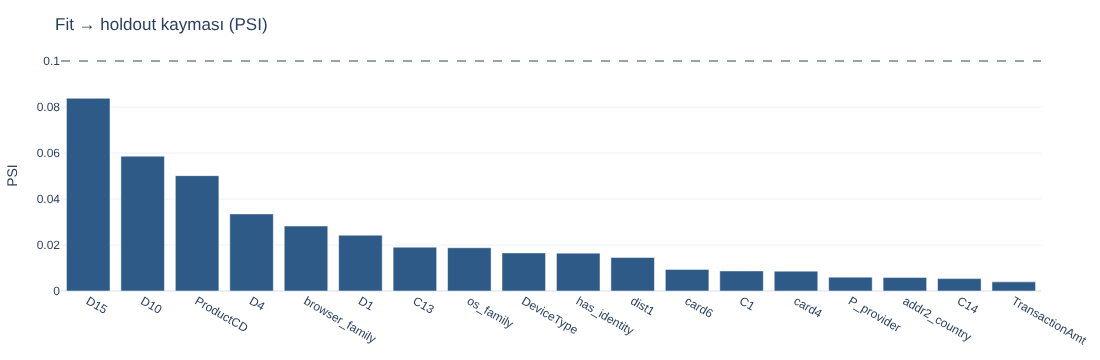

PSI > 0.1 olan kolonlar: yok


In [17]:
# Zaman içinde kayma: fit ile holdout arasında PSI (0,1 altı küçük, 0,1-0,25 orta, 0,25 üstü büyük)
def _dist_num(x, edges):
    x = x.astype("float64").to_numpy()
    b = np.digitize(x, edges[1:-1]).astype(float)
    b[np.isnan(x)] = -1
    return pd.Series(b).value_counts(normalize=True)

def psi(a, b, cat=False, bins=10):
    if cat:
        pa = a.astype("object").fillna("NA").value_counts(normalize=True)
        pb = b.astype("object").fillna("NA").value_counts(normalize=True)
    else:
        edges = np.unique(np.nanquantile(a.astype("float64"), np.linspace(0, 1, bins + 1)))
        pa, pb = _dist_num(a, edges), _dist_num(b, edges)
    idx = pa.index.union(pb.index)
    pa, pb = pa.reindex(idx, fill_value=0).clip(lower=1e-4), pb.reindex(idx, fill_value=0).clip(lower=1e-4)
    return float(((pa - pb) * np.log(pa / pb)).sum())

psi_num = ["TransactionAmt", "C1", "C13", "C14", "D1", "D4", "D10", "D15", "dist1"]
psi_cat = ["ProductCD", "card4", "card6", "P_provider", "DeviceType", "addr2_country", "has_identity", "os_family", "browser_family"]
drift = pd.Series({c: psi(df.loc[fit, c], df.loc[~fit, c]) for c in psi_num} |
                  {c: psi(df.loc[fit, c], df.loc[~fit, c], cat=True) for c in psi_cat}).sort_values(ascending=False)
display(drift.round(4).to_frame("PSI (fit → holdout)"))
fig = go.Figure(go.Bar(x=drift.index, y=drift.values, marker_color=[C_RISK if v > 0.1 else C_MAIN for v in drift.values]))
fig.add_hline(y=0.1, line_dash="dash", line_color=C_MUTED)
fig.update_layout(title="Fit → holdout kayması (PSI)", yaxis_title="PSI")
show(fig, 360)
note("PSI > 0.1 olan kolonlar", ", ".join(drift.index[drift > 0.1]) or "yok")

## 10. Outlier analizi

Her sayısal kolonda üç yöntem: ham IQR (1,5×), log1p ölçeğinde IQR (çarpık ve negatif olmayan kolonlar için daha anlamlı) ve robust z (MAD, |z| > 3,5). Değerlerin büyük kısmı aynıysa (IQR veya MAD sıfır) ilgili yöntem uygulanamaz ve tabloda boş görünür; o kolonlarda `max/p99` oranı uç değerin büyüklüğünü gösterir. Sonra tutar için ürün içi outlier'lar ve küçük bir örneklemde çok değişkenli (Isolation Forest) bir bakış.

,n,iqr_%,log_iqr_%,mad_z_%,p99,max,max/p99
C6,"590,540.0000",0.1326,0.1856,NaN,118.0000,"2,253.0000",19.0932
C14,"590,540.0000",0.1627,0.1806,NaN,128.0000,"1,429.0000",11.1641
C11,"590,540.0000",0.1267,0.1027,NaN,122.0000,"3,188.0000",26.1311
dist1,"238,269.0000",0.1678,0.0865,0.1836,"2,040.0000","10,286.0000",5.0422
C2,"590,540.0000",0.1054,0.0731,NaN,154.0000,"5,691.0000",36.9545
C1,"590,540.0000",0.1008,0.0689,NaN,164.0000,"4,685.0000",28.5671
C5,"590,540.0000",0.1024,0.0685,NaN,149.0000,349.0000,2.3423
id_02,"140,872.0000",0.0623,0.0493,0.0551,"770,898.3200","999,595.0000",1.2967
C9,"590,540.0000",0.0722,0.0423,0.0624,95.0000,210.0000,2.2105
C13,"590,540.0000",0.1281,0.0412,0.2353,578.0000,"2,918.0000",5.0484


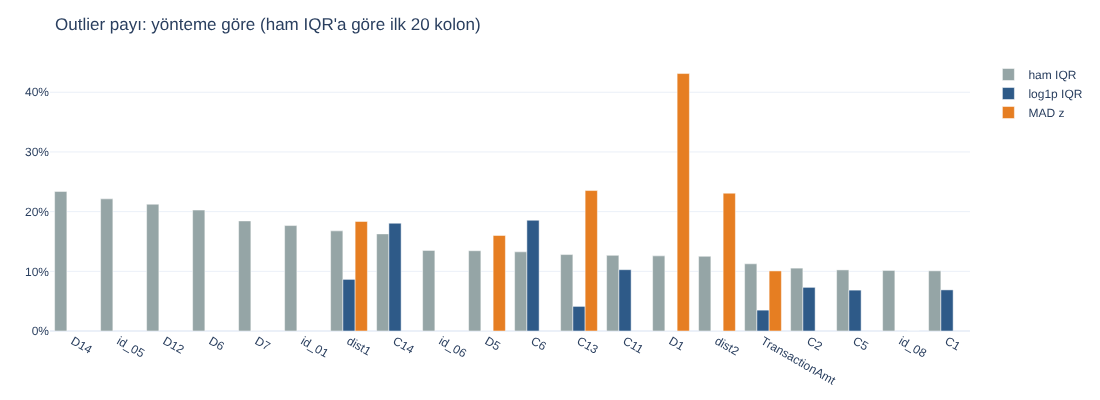

tutar outlier payı (log IQR): 0.0349


In [18]:
def outlier_stats(s):
    x = s.dropna().astype("float64").to_numpy()
    if len(x) < 100 or np.unique(x[:50_000]).size < 5:
        return None
    q1, q3 = np.percentile(x, [25, 75]); iqr = q3 - q1
    raw = np.mean((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)) if iqr > 0 else np.nan
    if x.min() >= 0:
        lx = np.log1p(x); l1, l3 = np.percentile(lx, [25, 75]); li = l3 - l1
        logiqr = np.mean((lx < l1 - 1.5 * li) | (lx > l3 + 1.5 * li)) if li > 0 else np.nan
    else:
        logiqr = np.nan
    med = np.median(x); mad = np.median(np.abs(x - med))
    rz = np.mean(np.abs(0.6745 * (x - med) / mad) > 3.5) if mad > 0 else np.nan
    p99 = np.percentile(x, 99)
    return {"n": len(x), "iqr_%": raw, "log_iqr_%": logiqr, "mad_z_%": rz, "p99": p99, "max": x.max(),
            "max/p99": x.max() / p99 if p99 > 0 else np.nan}

_o = {c: outlier_stats(df[c]) for c in core_num}
out = pd.DataFrame({c: v for c, v in _o.items() if v is not None}).T.astype("float64")
out = out.sort_values("log_iqr_%", ascending=False)
display(out.round(4))
top = out.sort_values("iqr_%", ascending=False).head(20)
fig = go.Figure()
for col, name, color in [("iqr_%", "ham IQR", C_MUTED), ("log_iqr_%", "log1p IQR", C_MAIN), ("mad_z_%", "MAD z", C_ACCENT)]:
    fig.add_trace(go.Bar(x=top.index, y=top[col], name=name, marker_color=color))
fig.update_layout(title="Outlier payı: yönteme göre (ham IQR'a göre ilk 20 kolon)", yaxis_tickformat=".0%", barmode="group")
show(fig, 400)
note("tutar outlier payı (log IQR)", round(float(out.loc["TransactionAmt", "log_iqr_%"]), 4))

,ürün içi tutar outlier payı
ProductCD,
C,0.0094
H,0.0016
R,0.0387
S,0.0037
W,0.0271


ürün içi tutar outlier payı: 0.0239


,en anormal %1 (medyan),diğerleri (medyan),en anormal %1 eksik,diğerleri eksik
TransactionAmt,59.0000,68.9500,0.0000,0.0000
C1,255.0000,1.0000,0.0000,0.0000
C2,228.0000,1.0000,0.0000,0.0000
C5,94.5000,0.0000,0.0000,0.0000
C6,178.5000,1.0000,0.0000,0.0000
C9,69.0000,1.0000,0.0000,0.0000
C11,192.5000,1.0000,0.0000,0.0000
C13,608.5000,2.0000,0.0000,0.0000
C14,173.0000,1.0000,0.0000,0.0000
D1,0.0000,1.0000,0.0000,0.0000


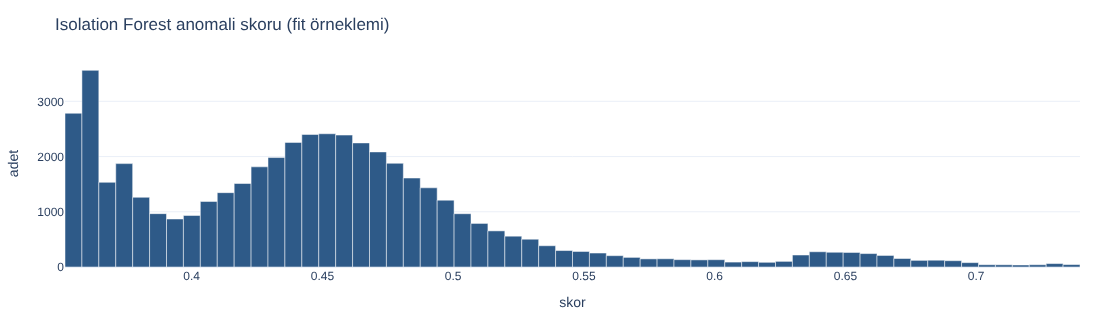

In [19]:
# Ürün içi tutar outlier'ı: aynı ürün tipinde log tutarın IQR dışında kalması
la = np.log1p(amt)
q1 = la.groupby(df["ProductCD"], observed=True).transform(lambda s: s.quantile(.25))
q3 = la.groupby(df["ProductCD"], observed=True).transform(lambda s: s.quantile(.75))
df["amt_outlier_in_product"] = (la > q3 + 1.5 * (q3 - q1)) | (la < q1 - 1.5 * (q3 - q1))
display(df.groupby("ProductCD", observed=True)["amt_outlier_in_product"].mean().round(4).to_frame("ürün içi tutar outlier payı"))
note("ürün içi tutar outlier payı", round(float(df["amt_outlier_in_product"].mean()), 4))

# Çok değişkenli bakış: küçük örneklemde Isolation Forest (yalnızca fit, etiketsiz)
from sklearn.ensemble import IsolationForest
iso_cols = ["TransactionAmt", "C1", "C2", "C5", "C6", "C9", "C11", "C13", "C14", "D1", "D4", "D10", "D15", "dist1"]
iso_cols = [c for c in iso_cols if c in df]
smp = df.loc[fit, iso_cols].sample(min(50_000, int(fit.sum())), random_state=SEED).astype("float64")
X = np.log1p(smp.clip(lower=0)).fillna(-1)
iso = IsolationForest(n_estimators=200, contamination="auto", random_state=SEED).fit(X)
score = -iso.score_samples(X)
top_mask = score >= np.quantile(score, 0.99)
cmp = pd.DataFrame({"en anormal %1 (medyan)": smp[top_mask].median(), "diğerleri (medyan)": smp[~top_mask].median(),
                    "en anormal %1 eksik": smp[top_mask].isna().mean(), "diğerleri eksik": smp[~top_mask].isna().mean()})
display(cmp.round(2))
show(hist_fig(score, bins=60, title="Isolation Forest anomali skoru (fit örneklemi)", xlabel="skor"), 320)

## 11. Kardinalite ve nadir kategoriler

Kategorik (ve sayısal görünümlü kod) kolonlarda farklı değer sayısı, nadir seviyeler (fit'te %0,1'den az görülen) ve holdout'ta fit'te hiç görülmemiş değerlerin payı. Sonuncusu online skorlamada "ilk kez görülen değer" sorununun büyüklüğünü gösterir.

,farklı (tümü),farklı (fit),eksik,"nadir seviye sayısı (<%0,1)",nadir seviyelerdeki satır payı,holdout'ta fit'te görülmemiş değer payı
kolon,,,,,,
card1,13553,12730,0.0000,12566,0.4378,0.0109
DeviceInfo,1786,1639,0.7991,1593,0.1576,0.0196
id_19,522,510,0.7641,451,0.0702,0.0014
card2,500,500,0.0151,402,0.1221,0.0000
id_21,490,444,0.9913,358,0.1269,0.0859
id_20,394,380,0.7642,309,0.0285,0.0019
id_25,341,317,0.9913,227,0.1072,0.0711
addr1,332,328,0.1113,273,0.0073,0.0001
id_33,260,212,0.8759,171,0.0186,0.0070


yüksek kardinalite (>1000): card1, DeviceInfo
orta kardinalite (100-1000): id_19, card2, id_21, id_20, id_25, addr1, id_33, id_31, card5, card3, id_17


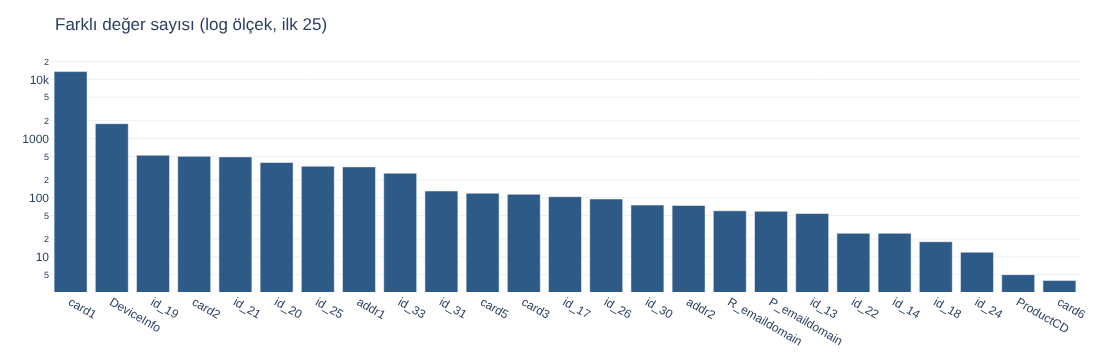

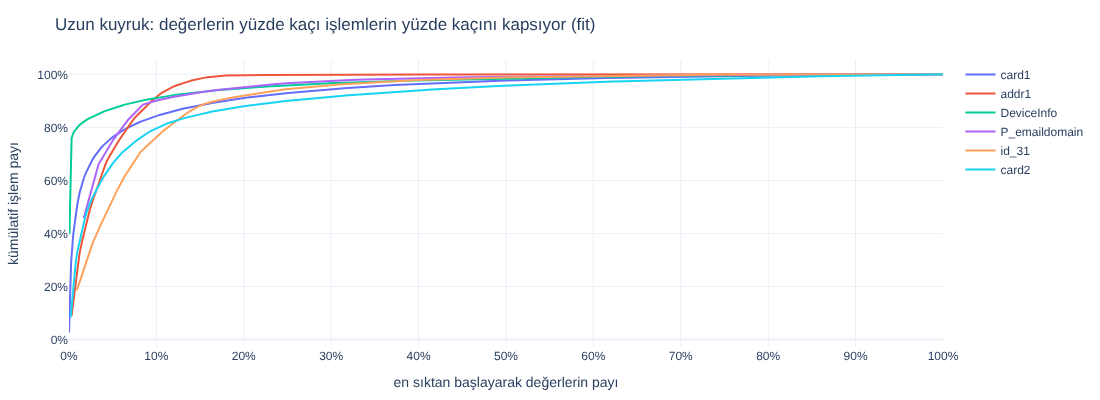

In [20]:
cat_cols = [c for c in types.index if (types.loc[c, "vesta_kategorik"] or types.loc[c, "çıkarılan_tip"].startswith("categorical"))
            and c in df.columns]
rows = []
for c in cat_cols:
    f_vc = df.loc[fit, c].astype("object").value_counts(normalize=True)
    rare = f_vc[f_vc < 0.001]
    h = df.loc[~fit, c].dropna().astype("object")
    rows.append({"kolon": c, "farklı (tümü)": df[c].nunique(), "farklı (fit)": len(f_vc), "eksik": df[c].isna().mean(),
                 "nadir seviye sayısı (<%0,1)": len(rare), "nadir seviyelerdeki satır payı": rare.sum(),
                 "holdout'ta fit'te görülmemiş değer payı": (~h.isin(f_vc.index)).mean() if len(h) else np.nan})
card = pd.DataFrame(rows).set_index("kolon").sort_values("farklı (tümü)", ascending=False)
display(card.round(4))
high = card[card["farklı (tümü)"] > 1000].index.tolist()
note("yüksek kardinalite (>1000)", ", ".join(high))
note("orta kardinalite (100-1000)", ", ".join(card[(card["farklı (tümü)"] > 100) & (card["farklı (tümü)"] <= 1000)].index))

t = card.head(25)
fig = go.Figure(go.Bar(x=t.index, y=t["farklı (tümü)"], marker_color=C_MAIN))
fig.update_layout(title="Farklı değer sayısı (log ölçek, ilk 25)", yaxis_type="log")
show(fig, 360)

fig = go.Figure()
for c in ["card1", "addr1", "DeviceInfo", "P_emaildomain", "id_31", "card2"]:
    if c in df:
        vc = df.loc[fit, c].value_counts(normalize=True).to_numpy()
        cum = np.cumsum(vc)
        x = np.arange(1, len(cum) + 1) / len(cum)
        step = max(1, len(cum) // 400)
        fig.add_trace(go.Scatter(x=x[::step], y=cum[::step], mode="lines", name=c))
fig.update_layout(title="Uzun kuyruk: değerlerin yüzde kaçı işlemlerin yüzde kaçını kapsıyor (fit)",
                  xaxis_title="en sıktan başlayarak değerlerin payı", yaxis_title="kümülatif işlem payı", xaxis_tickformat=".0%", yaxis_tickformat=".0%")
show(fig, 400)

## 12. Nadir kategorik kombinasyonlar

Tek tek sık görülen değerler bir arada nadir olabilir (ör. yaygın bir kart tipi + yaygın bir tarayıcı + nadir bir e-posta sağlayıcısı). Kombinasyon sıklıklarını fit'te sayıyorum; fit'te 10'dan az görülen kombinasyon "nadir". Holdout'ta fit'te hiç görülmemiş kombinasyonların payına da bakıyorum.

,gözlenen kombinasyon (fit),nadir kombinasyon (<10),nadir kombinasyondaki satır payı (fit),holdout'ta fit'te görülmemiş payı
kombinasyon,,,,
browser_family × P_provider,334,120,0.0009,0.0001
os_family × P_provider,233,76,0.0006,0.0001
card4 × P_provider,188,49,0.0004,0.0001
ProductCD × P_provider,157,23,0.0002,0.0000
card6 × P_provider,124,27,0.0002,0.0001
DeviceType × P_provider,133,13,0.0002,0.0000
P_provider × addr2_country,95,22,0.0001,0.0000
os_family × browser_family,49,17,0.0001,0.0000
DeviceType × os_family,17,7,0.0001,0.0000


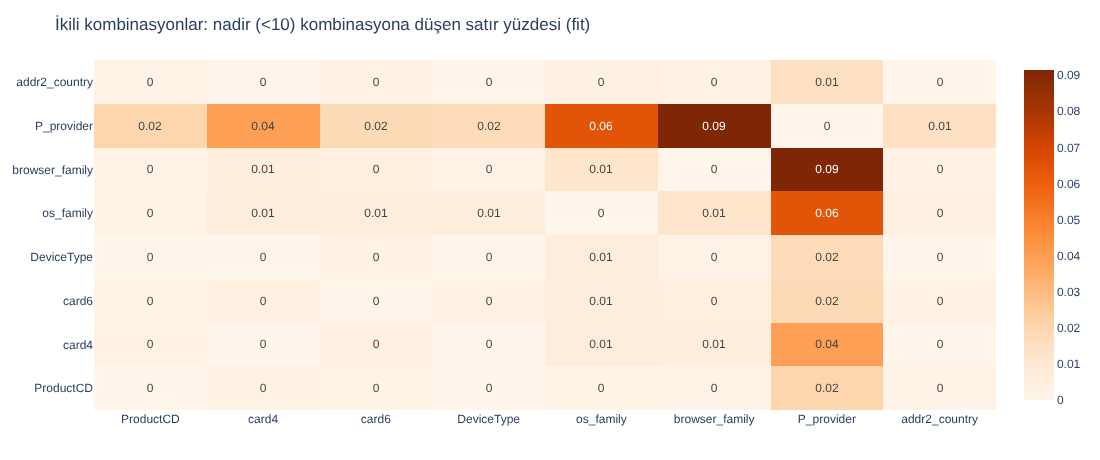

In [21]:
from itertools import combinations

combo_fields = ["ProductCD", "card4", "card6", "DeviceType", "os_family", "browser_family", "P_provider", "addr2_country"]
C = df[combo_fields].astype("object").fillna("NA")
RARE_N = 10

def combo_stats(cols):
    cols = list(cols)
    key = C[cols[0]].str.cat([C[c] for c in cols[1:]], sep="|") if len(cols) > 1 else C[cols[0]]
    f_counts = key[fit].value_counts()
    cnt_fit = key[fit].map(f_counts)
    hold_unseen = (~key[~fit].isin(f_counts.index)).mean()
    return key, f_counts, {"kombinasyon": " × ".join(cols), "gözlenen kombinasyon (fit)": len(f_counts),
                           "nadir kombinasyon (<10)": int((f_counts < RARE_N).sum()),
                           "nadir kombinasyondaki satır payı (fit)": float((cnt_fit < RARE_N).mean()),
                           "holdout'ta fit'te görülmemiş payı": float(hold_unseen)}

pair_rows = [combo_stats(p)[2] for p in combinations(combo_fields, 2)]
pairs = pd.DataFrame(pair_rows).set_index("kombinasyon").sort_values("nadir kombinasyondaki satır payı (fit)", ascending=False)
display(pairs.head(15).round(4))

mat = pd.DataFrame(0.0, index=combo_fields, columns=combo_fields)
for r in pair_rows:
    a, b = r["kombinasyon"].split(" × ")
    mat.loc[a, b] = mat.loc[b, a] = r["nadir kombinasyondaki satır payı (fit)"]
fig = go.Figure(go.Heatmap(z=mat.values * 100, x=combo_fields, y=combo_fields, colorscale="Oranges",
                           text=np.round(mat.values * 100, 2), texttemplate="%{text}"))
fig.update_layout(title="İkili kombinasyonlar: nadir (<10) kombinasyona düşen satır yüzdesi (fit)")
show(fig, 460)

In [22]:
triples = [("ProductCD", "card4", "card6"), ("DeviceType", "os_family", "browser_family"),
           ("card6", "P_provider", "addr2_country"), ("ProductCD", "DeviceType", "browser_family"),
           ("ProductCD", "card4", "card6", "DeviceType", "browser_family")]
tri_rows, keys = [], {}
for t in triples:
    key, f_counts, st = combo_stats(list(t))
    tri_rows.append(st); keys[t] = (key, f_counts)
tri = pd.DataFrame(tri_rows).set_index("kombinasyon")
display(tri.round(4))

main_combo = triples[-1]
key, f_counts = keys[main_combo]
df["combo_count_fit"] = key.map(f_counts).fillna(0).astype("int32")
df["rare_combo"] = df["combo_count_fit"] < RARE_N
print("Örnek nadir kombinasyonlar (fit'te 1-3 kez):")
ex = f_counts[(f_counts >= 1) & (f_counts <= 3)].head(12)
display(ex.rename("fit'te adet").to_frame())
note("nadir 5'li kombinasyon payı (fit)", round(float(df.loc[fit, "rare_combo"].mean()), 4))
note("5'li kombinasyon: holdout'ta görülmemiş payı", round(float(tri.iloc[-1]["holdout'ta fit'te görülmemiş payı"]), 4))

,gözlenen kombinasyon (fit),nadir kombinasyon (<10),nadir kombinasyondaki satır payı (fit),holdout'ta fit'te görülmemiş payı
kombinasyon,,,,
ProductCD × card4 × card6,46,10,0.0001,0.0000
DeviceType × os_family × browser_family,65,23,0.0001,0.0000
card6 × P_provider × addr2_country,218,79,0.0006,0.0002
ProductCD × DeviceType × browser_family,73,12,0.0001,0.0000
ProductCD × card4 × card6 × DeviceType × browser_family,407,166,0.0011,0.0001


Örnek nadir kombinasyonlar (fit'te 1-3 kez):


,fit'te adet
ProductCD,
R|american express|credit|mobile|android,3
R|mastercard|credit|desktop|opera,3
R|american express|credit|desktop|other,3
S|discover|credit|desktop|NA,3
C|visa|charge card|mobile|safari,3
R|mastercard|debit|desktop|opera,3
H|visa|debit|mobile|firefox,3
R|mastercard|debit|mobile|NA,3
S|american express|debit|desktop|ie,3


nadir 5'li kombinasyon payı (fit): 0.0011
5'li kombinasyon: holdout'ta görülmemiş payı: 0.0001


## 13. Kolon ilişkileri

- Sayısal çekirdek kolonlar arasında Spearman korelasyonu (fit'ten 100 bin satır) ve çok yüksek korelasyonlu (fazlalık) çiftler
- V kolonlarında fazlalık: |ρ| > 0,95 ile kaç temsilci kolon yeterli?
- Kategorikler arasında Cramér's V
- Tutar ile kategorikler arasında korelasyon oranı (η)
- D1 ile zaman arasındaki ilişki: `gün − D1` aynı kart grubunda sabit mi? (D1 = kart yaşı yorumunun testi)

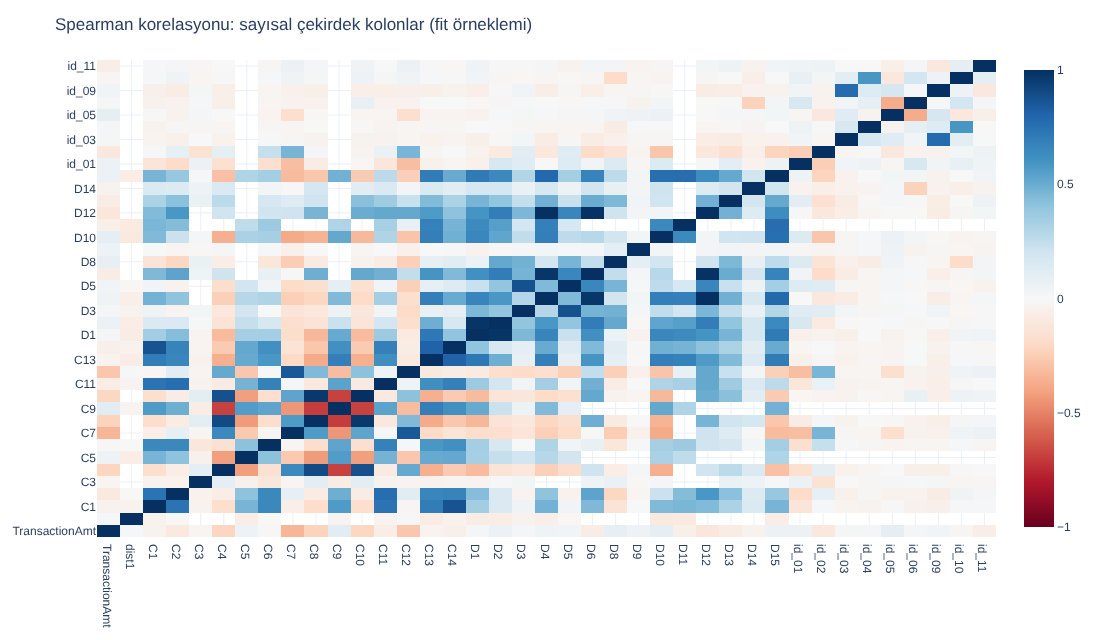

|ρ| > 0,9 olan çiftler:


,,rho,abs_rho
D4,D12,1.0000,1.0000
D6,D12,0.9930,0.9930
D1,D2,0.9800,0.9800
D4,D6,0.9780,0.9780
C8,C10,0.9710,0.9710
C4,C8,0.9040,0.9040


çekirdek kolonlarda |rho|>0.9 çift sayısı: 6


In [23]:
smp = df.loc[fit].sample(min(100_000, int(fit.sum())), random_state=SEED)
num_rel = [c for c in core_num if df[c].isna().mean() < 0.9]
rho = smp[num_rel].astype("float64").corr(method="spearman", min_periods=1000)
fig = go.Figure(go.Heatmap(z=rho.values, x=rho.columns, y=rho.index, colorscale="RdBu", zmin=-1, zmax=1))
fig.update_layout(title="Spearman korelasyonu: sayısal çekirdek kolonlar (fit örneklemi)")
show(fig, 640)

pairs_hi = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack().rename("rho").to_frame()
            .assign(abs_rho=lambda t: t["rho"].abs()).sort_values("abs_rho", ascending=False))
print("|ρ| > 0,9 olan çiftler:")
display(pairs_hi[pairs_hi["abs_rho"] > 0.9].head(25).round(3))
note("çekirdek kolonlarda |rho|>0.9 çift sayısı", int((pairs_hi["abs_rho"] > 0.9).sum()))

In [24]:
vs = df.loc[fit, v_cols].sample(min(30_000, int(fit.sum())), random_state=SEED).astype("float64")
vr = vs.rank().corr(min_periods=500).abs()
hi = (vr.where(np.triu(np.ones(vr.shape, dtype=bool), k=1)) > 0.95).sum().sum()
kept = []
for c in v_cols:
    if not kept or not (vr.loc[c, kept] > 0.95).any():
        kept.append(c)
note("V: |rho|>0.95 çift sayısı", int(hi))
note("V: |rho|>0.95 ile temsilci kolon sayısı", f"{len(kept)} / {len(v_cols)}")

V: |rho|>0.95 çift sayısı: 462
V: |rho|>0.95 ile temsilci kolon sayısı: 193 / 339


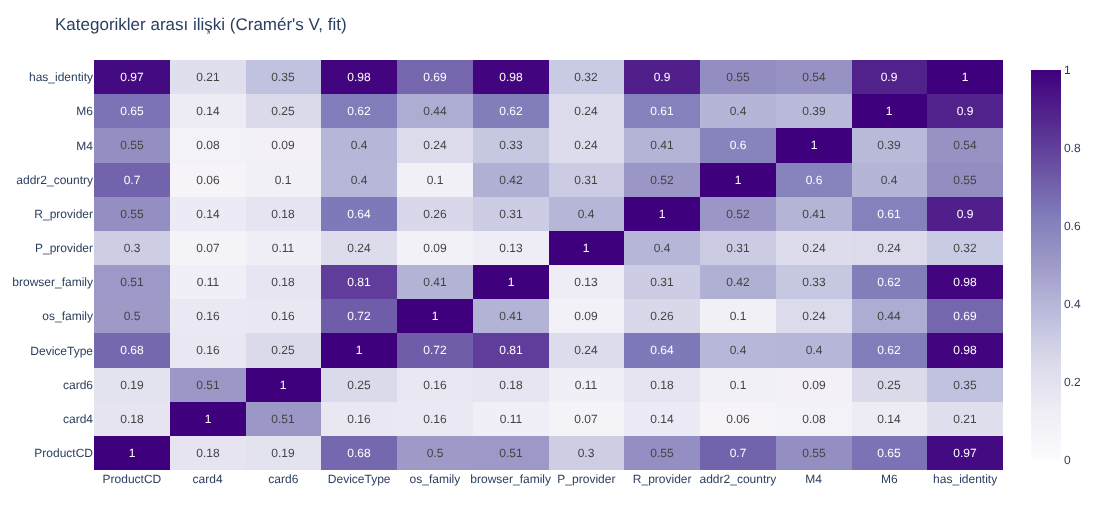

,η: log(tutar) ~ kategori
ProductCD,0.4110
addr2_country,0.3490
M4,0.2990
R_provider,0.2860
browser_family,0.2510
DeviceType,0.2380
M6,0.2380
has_identity,0.2310
P_provider,0.1900
card6,0.1390


In [25]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.to_numpy().sum(); r, k = ct.shape
    phi2c = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / max(1e-12, min(kc - 1, rc - 1))))

cv_fields = ["ProductCD", "card4", "card6", "DeviceType", "os_family", "browser_family", "P_provider", "R_provider",
             "addr2_country", "M4", "M6", "has_identity"]
Cf = df.loc[fit, cv_fields].astype("object").fillna("NA")
cv = pd.DataFrame(np.eye(len(cv_fields)), index=cv_fields, columns=cv_fields)
for a, b in combinations(cv_fields, 2):
    cv.loc[a, b] = cv.loc[b, a] = cramers_v(Cf[a], Cf[b])
fig = go.Figure(go.Heatmap(z=cv.values, x=cv_fields, y=cv_fields, colorscale="Purples", zmin=0, zmax=1,
                           text=np.round(cv.values, 2), texttemplate="%{text}"))
fig.update_layout(title="Kategorikler arası ilişki (Cramér's V, fit)")
show(fig, 520)

def eta(cat, num):
    d = pd.DataFrame({"c": cat.astype("object").fillna("NA"), "x": num}).dropna()
    m = d["x"].mean(); g = d.groupby("c")["x"].agg(["mean", "size"])
    return float(np.sqrt(((g["mean"] - m) ** 2 * g["size"]).sum() / ((d["x"] - m) ** 2).sum()))

la_fit = np.log1p(df.loc[fit, "TransactionAmt"].astype("float64"))
eta_tbl = pd.Series({c: eta(df.loc[fit, c], la_fit) for c in cv_fields}).sort_values(ascending=False)
display(eta_tbl.round(3).to_frame("η: log(tutar) ~ kategori"))

In [26]:
# D1 = kart yaşı mı? Kartın ilk görüldüğü gün = gün - D1. Aynı kart grubunda bu değer sabit olmalı.
df["entity"] = df["card1"].astype(str) + "_" + df["addr1"].astype("object").fillna("NA").astype(str)
df["D1n"] = df["day"] - df["D1"]
e = df.loc[fit & df["D1"].notna(), ["entity", "D1n"]]
big = e[e.groupby("entity")["D1n"].transform("size") >= 5]
real = big.groupby("entity")["D1n"].nunique()
shuf = big.assign(D1n=rng.permutation(big["D1n"].to_numpy())).groupby("entity")["D1n"].nunique()
cmp = pd.DataFrame({"gerçek": real.describe(percentiles=[.5, .9]), "karıştırılmış": shuf.describe(percentiles=[.5, .9])})
display(cmp.round(1))
note("entity başına farklı D1n (medyan) gerçek/karıştırılmış", f"{real.median():.0f} / {shuf.median():.0f}")

,gerçek,karıştırılmış
count,"11,505.0000","11,505.0000"
mean,12.9000,25.9000
std,26.0000,45.8000
min,1.0000,4.0000
50%,5.0000,11.0000
90%,27.0000,55.0000
max,451.0000,628.0000


entity başına farklı D1n (medyan) gerçek/karıştırılmış: 5 / 11


## 14. Zaman desenleri

Saatlik hacim ve saat kayması, en düşük hacimli 6 saat (fit'ten), tahmini yerel saat, iş saati ve hafta sonu payları, saat × gün ısı haritası, günlük hacimden tatil sezonunu öğrenme ve resmi tatillerle karşılaştırma.

Not: `TransactionDT`'nin başlangıç anı gece yarısı olmayabilir; bu yüzden ham saat gerçek yerel saat değildir. Gerçek yerel saatte en sakin dönem gece olmalı. Ham saatte en düşük hacimli 6 saatlik pencereyi bulup onu 00-06'ya kaydırarak `local_hour_est` (tahmini yerel saat) üretiyorum. İş saati ve hafta sonu feature'ları bu tahmine ve bölüm 7'deki başlangıç tarihi varsayımına bağlıdır.

en düşük hacimli 6 saat (ham): 06:00-12:00
düşük hacim penceresi payı (fit): 0.0407
iş saati payı (tahmini yerel 09-18, hafta içi): 0.4231
hafta sonu payı: 0.302


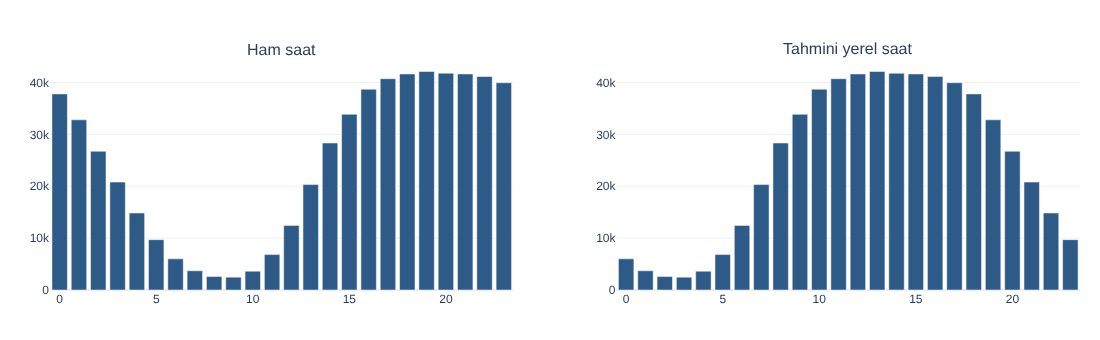

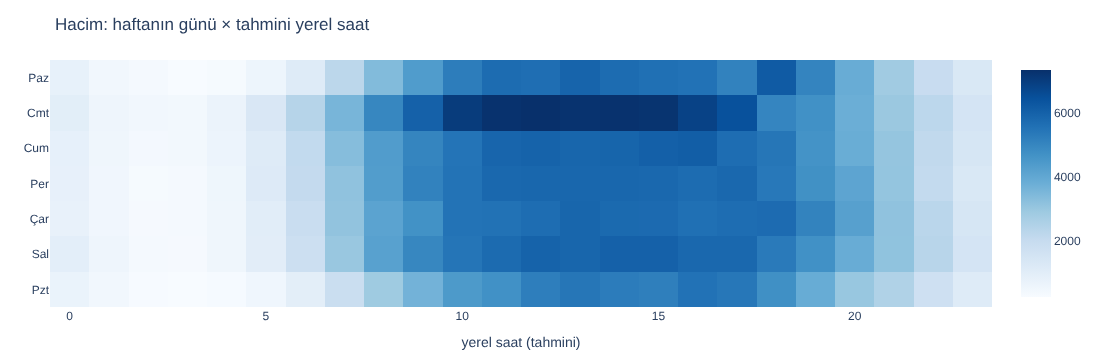

,pay
dow,
Pzt,0.1189
Sal,0.1447
Çar,0.1436
Per,0.1445
Cum,0.1463
Cmt,0.1668
Paz,0.1352


Yerel saate göre medyan tutar: {0: 59.0, 1: 62.70000076293945, 2: 68.0, 3: 78.5, 4: 77.0, 5: 75.0, 6: 77.0, 7: 78.5, 8: 83.0, 9: 78.0, 10: 77.0, 11: 77.0, 12: 75.5999984741211, 13: 75.0, 14: 75.0, 15: 73.0, 16: 68.0, 17: 62.0, 18: 59.0, 19: 59.0, 20: 59.0, 21: 59.0, 22: 59.0, 23: 58.0}


In [27]:
h_fit = df.loc[fit].groupby("hour").size().reindex(range(24), fill_value=0)
win = pd.Series({s: h_fit[[(s + k) % 24 for k in range(6)]].sum() for s in range(24)})
LOW_START = int(win.idxmin())
df["local_hour_est"] = ((df["hour"] - LOW_START) % 24).astype("int8")   # düşük hacim penceresi -> 00-06
df["is_low_volume_window"] = df["local_hour_est"] < 6
df["is_weekend"] = df["dow"] >= 5
df["is_business_hours"] = (~df["is_weekend"]) & df["local_hour_est"].between(9, 17)
note("en düşük hacimli 6 saat (ham)", f"{LOW_START:02d}:00-{(LOW_START + 6) % 24:02d}:00")
note("düşük hacim penceresi payı (fit)", round(float(df.loc[fit, "is_low_volume_window"].mean()), 4))
note("iş saati payı (tahmini yerel 09-18, hafta içi)", round(float(df["is_business_hours"].mean()), 4))
note("hafta sonu payı", round(float(df["is_weekend"].mean()), 4))

fig = make_subplots(rows=1, cols=2, subplot_titles=("Ham saat", "Tahmini yerel saat"))
for i, col in enumerate(["hour", "local_hour_est"], start=1):
    hc = df.groupby(col).size()
    fig.add_trace(go.Bar(x=hc.index, y=hc.values, marker_color=C_MAIN, showlegend=False), 1, i)
show(fig, 340)

hm = df.groupby(["dow", "local_hour_est"]).size().unstack(fill_value=0)
fig = go.Figure(go.Heatmap(z=hm.values, x=hm.columns, y=["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"][:len(hm)], colorscale="Blues"))
fig.update_layout(title="Hacim: haftanın günü × tahmini yerel saat", xaxis_title="yerel saat (tahmini)")
show(fig, 360)
display((df["dow"].value_counts(normalize=True).sort_index()).round(4).rename(index=dict(enumerate(["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]))).to_frame("pay"))
med_amt_h = df.groupby("local_hour_est")["TransactionAmt"].median()
print("Yerel saate göre medyan tutar:", med_amt_h.round(1).to_dict())

veriden öğrenilen yoğun sezon: 2017-12-19 - 2017-12-26 (8 gün, eşik 1.25)


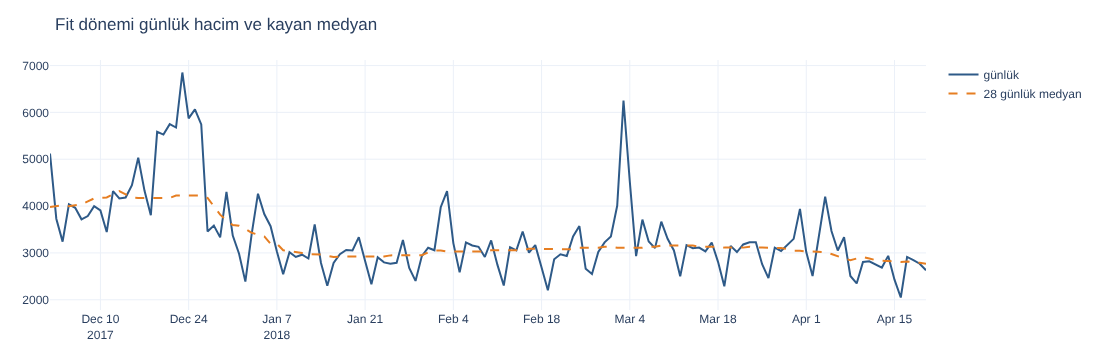

,oran,tarih
day,,
92,2.0110,2018-03-03
22,1.6220,2017-12-23
93,1.4550,2018-03-04
24,1.4360,2017-12-25
64,1.4250,2018-02-03
124,1.3930,2018-04-04
23,1.3900,2017-12-24
20,1.3780,2017-12-21
25,1.3600,2017-12-26


resmi tatil / diğer gün günlük ort.: 3124 / 3248


In [28]:
daily = df.loc[fit].groupby("day").size()
daily = daily.iloc[:-1]                    # fit'in son günü yarım (sınır günü), grafikte yanıltıcı düşüş yapar
base = daily.rolling(28, center=True, min_periods=7).median()
ratio = (daily / base).rename("oran")
SEASON_THR = 1.25
hot = ratio[ratio > SEASON_THR]
runs, cur = [], []
for d in hot.index:
    if cur and d != cur[-1] + 1:
        runs.append(cur); cur = []
    cur.append(d)
if cur:
    runs.append(cur)
season = max(runs, key=len) if runs else []
if season:
    s0, s1 = (REF_DATE + pd.Timedelta(days=season[0])).date(), (REF_DATE + pd.Timedelta(days=season[-1])).date()
    note("veriden öğrenilen yoğun sezon", f"{s0} - {s1} ({len(season)} gün, eşik {SEASON_THR})")
df["holiday_season"] = df["day"].isin(season)

fig = go.Figure()
fig.add_trace(go.Scatter(x=REF_DATE + pd.to_timedelta(daily.index, unit="D"), y=daily.values, name="günlük", line=dict(color=C_MAIN)))
fig.add_trace(go.Scatter(x=REF_DATE + pd.to_timedelta(base.index, unit="D"), y=base.values, name="28 günlük medyan", line=dict(color=C_ACCENT, dash="dash")))
fig.update_layout(title="Fit dönemi günlük hacim ve kayan medyan")
show(fig, 360)
display(ratio.sort_values(ascending=False).head(10).round(3).to_frame()
        .assign(tarih=lambda t: (REF_DATE + pd.to_timedelta(t.index, unit="D")).date))

US_HOLIDAYS = pd.to_datetime(["2017-12-25", "2018-01-01", "2018-01-15", "2018-02-19", "2018-05-28"])
df["is_us_holiday"] = df["dt"].dt.normalize().isin(US_HOLIDAYS)
hd = df.groupby([df["dt"].dt.normalize(), "is_us_holiday"]).size().groupby("is_us_holiday").mean()
note("resmi tatil / diğer gün günlük ort.", f"{hd.get(True, np.nan):.0f} / {hd.get(False, np.nan):.0f}")

## 15. Entity davranışı

Gerçek kullanıcı kimliği yok. Farklı entity tanımlarını karşılaştırıyorum (boyut dağılımı, holdout'ta tanınma oranı), sonra seçilen tanımla (card1 + addr1) işlem aralıkları, velocity, tutar tutarlılığı, entity başına farklı e-posta/cihaz sayısı ve en "patlamalı" entity'ler.

,entity sayısı,medyan işlem,p99,en büyük,tek işlemli entity payı,holdout'ta fit'te görülmüş payı
tanım,,,,,,
card1,13553,4.0000,786.4400,14932,0.2540,0.9890
card1+addr1,39974,2.0000,201.2700,9928,0.3940,0.9580
card1+addr1+P_email,90375,2.0000,76.0000,4015,0.4840,0.8840
card1+addr1+D1n,217850,1.0000,20.0000,1414,0.5750,0.4350


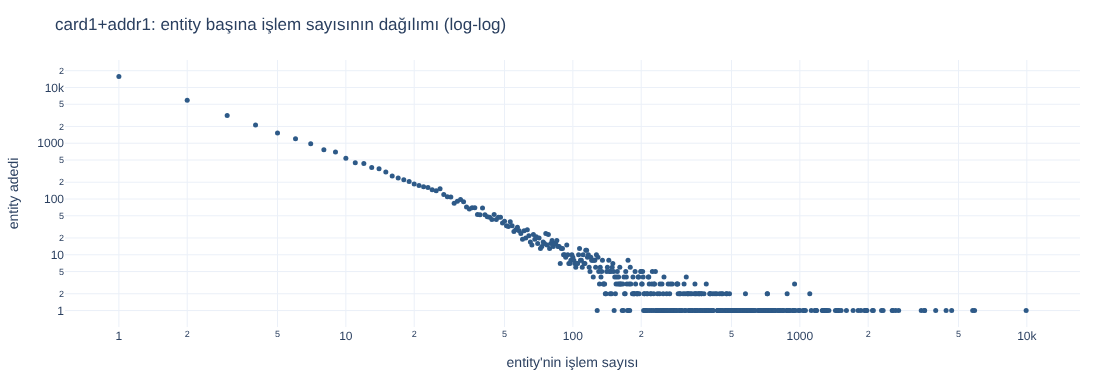

entity sayısı (card1+addr1): 39974
entity holdout tanınma oranı: 0.9578


In [29]:
defs = {"card1": df["card1"].astype(str),
        "card1+addr1": df["entity"],
        "card1+addr1+P_email": df["entity"] + "_" + df["P_emaildomain"].astype("object").fillna("NA").astype(str),
        "card1+addr1+D1n": df["entity"] + "_" + df["D1n"].astype("object").fillna("NA").astype(str)}
rows = []
for name, key in defs.items():
    size = key.value_counts()
    fit_keys = key[fit].unique()
    rows.append({"tanım": name, "entity sayısı": len(size), "medyan işlem": size.median(), "p99": size.quantile(.99),
                 "en büyük": size.max(), "tek işlemli entity payı": (size == 1).mean(),
                 "holdout'ta fit'te görülmüş payı": key[~fit].isin(fit_keys).mean()})
ent_defs = pd.DataFrame(rows).set_index("tanım")
display(ent_defs.round(3))

size = df["entity"].value_counts()
vc = size.value_counts().sort_index()
fig = go.Figure(go.Scatter(x=vc.index, y=vc.values, mode="markers", marker=dict(color=C_MAIN, size=5)))
fig.update_layout(title="card1+addr1: entity başına işlem sayısının dağılımı (log-log)", xaxis_type="log", yaxis_type="log",
                  xaxis_title="entity'nin işlem sayısı", yaxis_title="entity adedi")
show(fig, 380)
note("entity sayısı (card1+addr1)", len(size))
note("entity holdout tanınma oranı", round(float(ent_defs.loc["card1+addr1", "holdout'ta fit'te görülmüş payı"]), 4))

,count,mean,std,min,50%,90%,99%,max
vel_1h,"590,540.0000",0.6500,4.6900,0.0000,0.0000,2.0000,6.0000,191.0000
vel_24h,"590,540.0000",5.9400,24.0300,0.0000,1.0000,15.0000,63.0000,880.0000
secs_since_prev,"550,566.0000","369,716.5000","1,078,212.1000",0.0000,"36,081.0000","902,999.0000","5,697,425.1500","15,599,674.0000"
amt_to_ent_avg,"550,566.0000",1.1400,1.9000,0.0000,0.7100,2.1800,8.1000,234.9800
ent_txn_count,"590,540.0000",392.0600,991.7900,0.0000,48.0000,"1,024.0000","5,226.6100","9,927.0000"


1 saatte >=2 önceki işlem payı: 0.1022
vel_1h p99 / max: 6 / 191


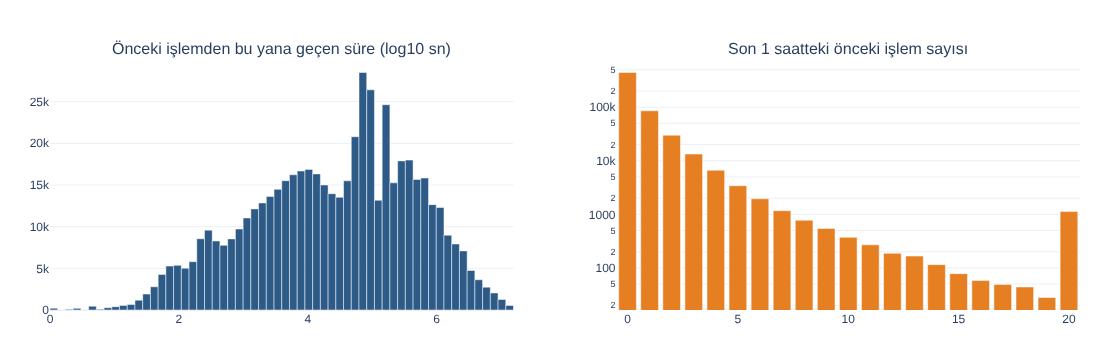

In [30]:
def window_sum(ent_codes, ts, window, w=None):
    """Aynı entity'de [t - window, t) aralığındaki ÖNCEKİ satırların toplamı (w yoksa adet)."""
    key = ent_codes.astype("int64") * 10**9 + ts.astype("int64")
    order = np.argsort(key, kind="stable")
    ks = key[order]
    ws = np.ones(len(ks)) if w is None else np.asarray(w, dtype="float64")[order]
    cs = np.concatenate([[0.0], np.cumsum(ws)])
    left = np.searchsorted(ks, ks - window, side="left")
    out = np.empty(len(ks)); out[order] = cs[np.arange(len(ks))] - cs[left]
    return out

ent_code = df["entity"].astype("category").cat.codes.to_numpy()
ts = df["TransactionDT"].to_numpy()
df["vel_1h"] = window_sum(ent_code, ts, 3600)
df["vel_24h"] = window_sum(ent_code, ts, DAY)

g = df.groupby("entity", sort=False)
a64 = df["TransactionAmt"].astype("float64")
df["ent_txn_count"] = g.cumcount()                                         # case: user_transaction_count
cs = a64.groupby(df["entity"], sort=False).cumsum() - a64
cs2 = (a64 ** 2).groupby(df["entity"], sort=False).cumsum() - a64 ** 2
n_prev = df["ent_txn_count"].replace(0, np.nan)
df["ent_avg_amt"] = cs / n_prev                                            # case: user_avg_amount
df["ent_std_amt"] = np.sqrt(((cs2 / n_prev) - df["ent_avg_amt"] ** 2).clip(lower=0))
df["amt_to_ent_avg"] = a64 / df["ent_avg_amt"]
# z-skoru yalnızca en az 2 önceki işlem ve anlamlı bir yayılım (std >= 1 USD) varsa; uç değerler ±50'de kırpılır
_std = df["ent_std_amt"].where((df["ent_txn_count"] >= 2) & (df["ent_std_amt"] >= 1.0))
df["ent_amt_z"] = ((a64 - df["ent_avg_amt"]) / _std).clip(-50, 50)
df["secs_since_prev"] = df["TransactionDT"] - g["TransactionDT"].shift(1)

vel = df[["vel_1h", "vel_24h", "secs_since_prev", "amt_to_ent_avg", "ent_txn_count"]].describe(percentiles=[.5, .9, .99]).T
display(vel.round(2))
note("1 saatte >=2 önceki işlem payı", round(float((df["vel_1h"] >= 2).mean()), 4))
note("vel_1h p99 / max", f"{df['vel_1h'].quantile(.99):.0f} / {df['vel_1h'].max():.0f}")

fig = make_subplots(rows=1, cols=2, subplot_titles=("Önceki işlemden bu yana geçen süre (log10 sn)", "Son 1 saatteki önceki işlem sayısı"))
v = np.log10(df["secs_since_prev"].dropna().clip(lower=1))
cnt, edges = np.histogram(v, bins=60)
fig.add_trace(go.Bar(x=(edges[:-1] + edges[1:]) / 2, y=cnt, width=np.diff(edges), marker_color=C_MAIN, showlegend=False), 1, 1)
vc = df["vel_1h"].clip(upper=20).value_counts().sort_index()
fig.add_trace(go.Bar(x=vc.index, y=vc.values, marker_color=C_ACCENT, showlegend=False), 1, 2)
fig.update_yaxes(type="log", row=1, col=2)
show(fig, 360)

,count,mean,std,min,50%,90%,99%,max
işlem,"13,056.0000",41.7500,183.7500,5.0000,12.0000,69.0000,525.9000,"9,928.0000"
farklı_email,"13,056.0000",3.6800,2.9400,0.0000,3.0000,7.0000,15.0000,32.0000
farklı_cihaz,"13,056.0000",2.0400,10.4800,0.0000,1.0000,4.0000,15.0000,609.0000
farklı_ürün,"13,056.0000",1.8200,0.9600,1.0000,1.0000,3.0000,4.0000,5.0000
tutar_cv,"13,056.0000",0.8300,0.4700,0.0000,0.7500,1.4800,2.2300,4.0400
max_vel_1h,"13,056.0000",1.3900,2.3000,0.0000,1.0000,3.0000,7.0000,191.0000


En patlamalı 5 entity (1 saatte en çok işlem):


,işlem,farklı_email,farklı_cihaz,farklı_ürün,tutar_cv,max_vel_1h
entity,,,,,,
15775_330.0,1453,0,2,2,0.2941,191.0000
15885_NA,9928,21,609,1,0.9185,26.0000
9917_NA,886,13,133,1,0.8665,26.0000
16136_NA,1975,12,267,1,1.0537,23.0000
14276_NA,837,14,129,1,0.9940,21.0000


en patlamalı entity: 15775_330.0 (1 saatte 191 önceki işlem)


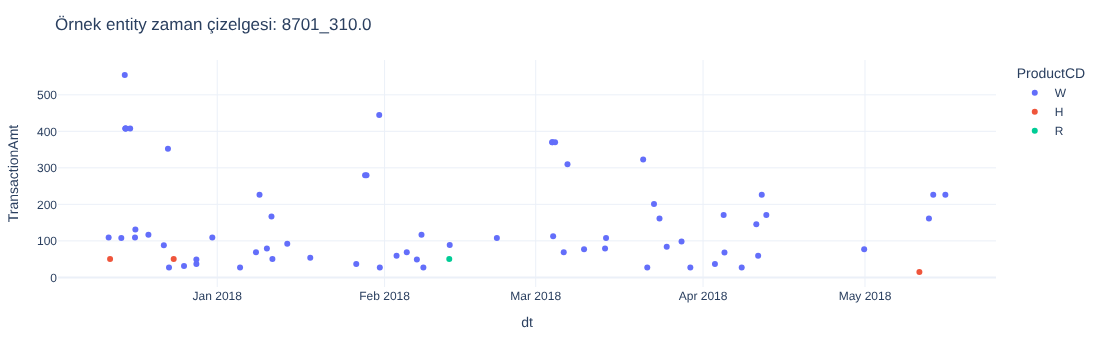

In [31]:
per_ent = df.groupby("entity").agg(işlem=("TransactionID", "size"),
                                   farklı_email=("P_emaildomain", "nunique"),
                                   farklı_cihaz=("DeviceInfo", "nunique"),
                                   farklı_ürün=("ProductCD", "nunique"),
                                   tutar_cv=("TransactionAmt", lambda s: s.std() / s.mean() if len(s) > 1 and s.mean() > 0 else np.nan),
                                   max_vel_1h=("vel_1h", "max"))
display(per_ent[per_ent["işlem"] >= 5].describe(percentiles=[.5, .9, .99]).T.round(2))
print("En patlamalı 5 entity (1 saatte en çok işlem):")
display(per_ent.sort_values("max_vel_1h", ascending=False).head(5))
burst = per_ent["max_vel_1h"].idxmax()
note("en patlamalı entity", f"{burst} (1 saatte {per_ent.loc[burst, 'max_vel_1h']:.0f} önceki işlem)")

mid = per_ent[(per_ent["işlem"] > 30) & (per_ent["işlem"] < 80)].index
if len(mid):
    e = rng.choice(mid)
    h = df[df["entity"] == e]
    fig = px.scatter(h, x="dt", y="TransactionAmt", color="ProductCD", title=f"Örnek entity zaman çizelgesi: {e}")
    show(fig, 340)

## 16. Feature keşfi (Adım 3)

Case'in istediği dört grupta, yalnızca geçmiş işlemlerden hesaplanan örnek feature'lar. Case'deki `user_*` isimlerinin karşılığı entity (card1 + addr1, kart grubu) bazlı feature'lardır; tabloda eşleme açıkça yazılı.

In [32]:
# relational
both_email = df["P_emaildomain"].notna() & df["R_emaildomain"].notna()
df["email_mismatch"] = both_email & (df["P_emaildomain"].astype("object") != df["R_emaildomain"].astype("object"))
df["foreign_addr2"] = df["addr2"].notna() & (df["addr2"] != dom_addr2)
df["addr2_missing"] = df["addr2"].isna()
card_prev = df.groupby("card1", sort=False).cumcount()
df["card_new_addr"] = (card_prev > 0) & (df["ent_txn_count"] == 0)
dev_key = df["entity"] + "|" + df["DeviceInfo"].astype("object").fillna("NA").astype(str)
df["new_device_for_entity"] = df["DeviceInfo"].notna() & (df["ent_txn_count"] > 0) & (dev_key.groupby(dev_key, sort=False).cumcount() == 0)
em_key = df["entity"] + "|" + df["P_emaildomain"].astype("object").fillna("NA").astype(str)
df["new_email_for_entity"] = df["P_emaildomain"].notna() & (df["ent_txn_count"] > 0) & (em_key.groupby(em_key, sort=False).cumcount() == 0)
# context / tutar
df["card_age_days"] = df["D1"]
df["is_new_card"] = df["D1"] == 0
amt_freq = df.loc[fit, "TransactionAmt"].round(2).value_counts(normalize=True)
df["amt_freq"] = df["TransactionAmt"].round(2).map(amt_freq).fillna(0)
df["amt_is_round"] = (df["TransactionAmt"] % 1 == 0)

catalog = pd.DataFrame([
    ("hour", "temporal", "ham saat", "hour"),
    ("local_hour_est", "temporal", "tahmini yerel saat (düşük hacim penceresi 00-06'ya kaydırıldı)", ""),
    ("dow", "temporal", "haftanın günü", "day_of_week"),
    ("is_weekend", "temporal", "hafta sonu", "is_weekend"),
    ("is_business_hours", "temporal", "hafta içi, tahmini yerel 09-18", ""),
    ("is_low_volume_window", "temporal", "en düşük hacimli 6 saat (gece vekili)", ""),
    ("holiday_season", "temporal", "veriden öğrenilen yoğun sezon", ""),
    ("ent_txn_count", "entity", "entity'nin bu işlemden önceki işlem sayısı", "user_transaction_count"),
    ("ent_avg_amt", "entity", "entity'nin önceki işlemlerinin ortalama tutarı", "user_avg_amount"),
    ("amt_to_ent_avg", "entity", "tutar / entity ortalaması", ""),
    ("ent_amt_z", "entity", "tutarın entity geçmişine göre z-skoru", ""),
    ("secs_since_prev", "entity", "entity'nin önceki işleminden bu yana saniye", ""),
    ("vel_1h", "entity", "son 1 saatteki önceki işlem sayısı", ""),
    ("vel_24h", "entity", "son 24 saatteki önceki işlem sayısı", ""),
    ("email_mismatch", "relational", "alıcı ve karşı taraf e-posta alanı farklı (ikisi de dolu)", ""),
    ("foreign_addr2", "relational", "fatura ülkesi baskın ülke değil", ""),
    ("addr2_missing", "relational", "fatura ülkesi eksik", ""),
    ("card_new_addr", "relational", "kart daha önce görülmüş ama bu adresle ilk kez", ""),
    ("new_device_for_entity", "relational", "entity için yeni cihaz", ""),
    ("new_email_for_entity", "relational", "entity için yeni e-posta alanı", ""),
    ("has_identity", "context", "identity kaydı var", ""),
    ("card_age_days", "context", "kart yaşı (D1, gün)", ""),
    ("is_new_card", "context", "kartın ilk günü (D1 = 0)", ""),
    ("amt_decimals", "context", "tutarın ondalık basamak sayısı", ""),
    ("amt_freq", "context", "bu tutarın fit'teki sıklığı", ""),
    ("amt_is_round", "context", "tam sayı tutar", ""),
    ("rare_combo", "context", "5'li kategorik kombinasyon fit'te nadir", ""),
    ("amt_outlier_in_product", "context", "ürün içinde tutar outlier'ı", ""),
], columns=["feature", "grup", "açıklama", "case'deki isim"]).set_index("feature")
display(catalog)
feat_cols = catalog.index.tolist()
fs = df[feat_cols].astype("float64").describe(percentiles=[.5, .9]).T
fs["eksik"] = df[feat_cols].isna().mean()
display(fs.round(3))

,grup,açıklama,case'deki isim
feature,,,
hour,temporal,ham saat,hour
local_hour_est,temporal,tahmini yerel saat (düşük hacim penceresi 00-06'ya kaydırıldı),
dow,temporal,haftanın günü,day_of_week
is_weekend,temporal,hafta sonu,is_weekend
is_business_hours,temporal,"hafta içi, tahmini yerel 09-18",
is_low_volume_window,temporal,en düşük hacimli 6 saat (gece vekili),
holiday_season,temporal,veriden öğrenilen yoğun sezon,
ent_txn_count,entity,entity'nin bu işlemden önceki işlem sayısı,user_transaction_count
ent_avg_amt,entity,entity'nin önceki işlemlerinin ortalama tutarı,user_avg_amount


,count,mean,std,min,50%,90%,max,eksik
hour,"590,540.0000",13.8620,7.6070,0.0000,16.0000,22.0000,23.0000,0.0000
local_hour_est,"590,540.0000",13.6600,4.8490,0.0000,14.0000,20.0000,23.0000,0.0000
dow,"590,540.0000",3.0960,1.9530,0.0000,3.0000,6.0000,6.0000,0.0000
is_weekend,"590,540.0000",0.3020,0.4590,0.0000,0.0000,1.0000,1.0000,0.0000
is_business_hours,"590,540.0000",0.4230,0.4940,0.0000,0.0000,1.0000,1.0000,0.0000
is_low_volume_window,"590,540.0000",0.0430,0.2020,0.0000,0.0000,0.0000,1.0000,0.0000
holiday_season,"590,540.0000",0.0800,0.2710,0.0000,0.0000,0.0000,1.0000,0.0000
ent_txn_count,"590,540.0000",392.0570,991.7920,0.0000,48.0000,"1,024.0000","9,927.0000",0.0000
ent_avg_amt,"550,566.0000",128.0100,108.6250,0.4240,109.5350,213.3950,"5,279.9500",0.0680
amt_to_ent_avg,"550,566.0000",1.1450,1.9010,0.0040,0.7150,2.1840,234.9850,0.0680


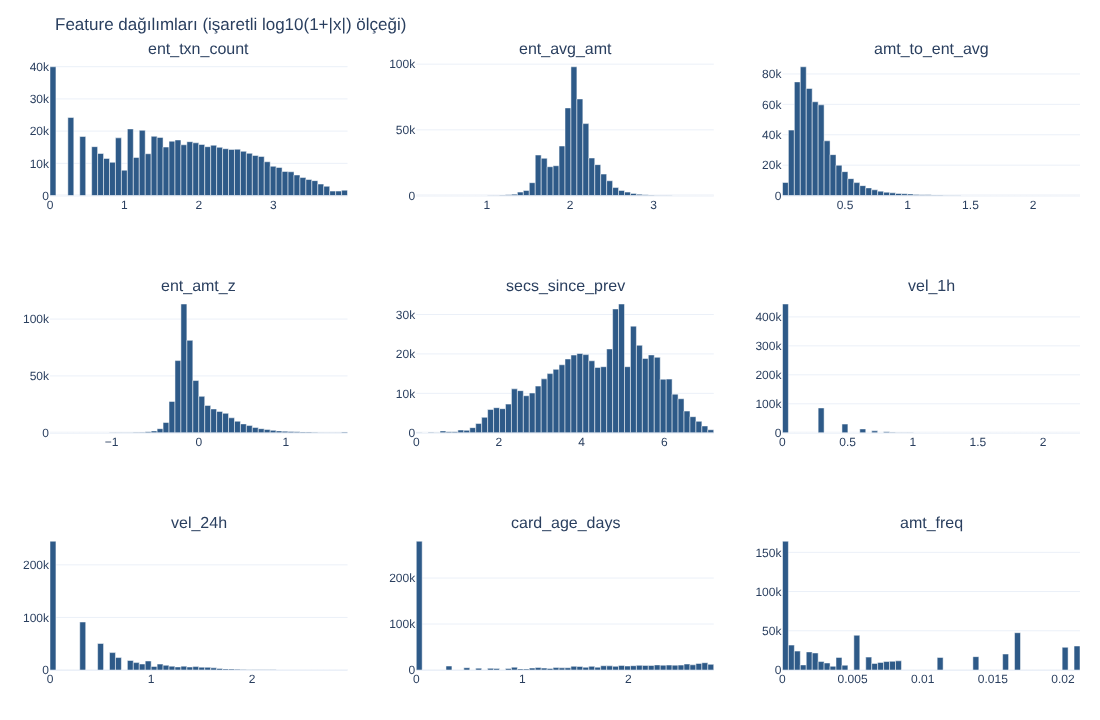

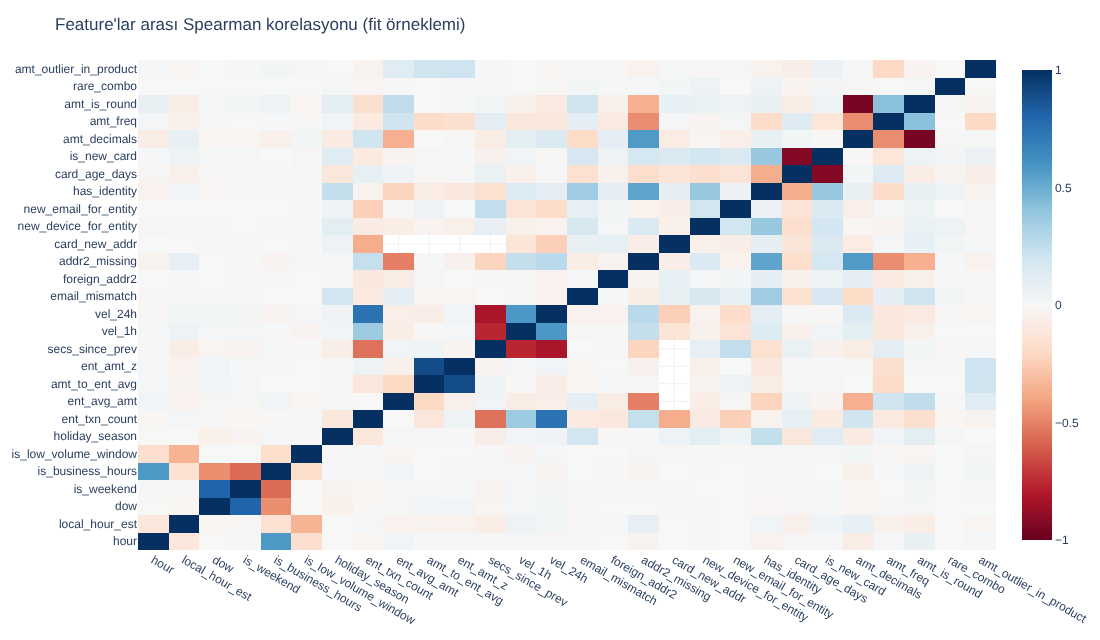

,,rho
dow,is_weekend,0.8070
amt_to_ent_avg,ent_amt_z,0.8970
secs_since_prev,vel_24h,-0.8210
card_age_days,is_new_card,-0.9220
amt_decimals,amt_is_round,-0.9540


In [33]:
num_feats = ["ent_txn_count", "ent_avg_amt", "amt_to_ent_avg", "ent_amt_z", "secs_since_prev", "vel_1h", "vel_24h", "card_age_days", "amt_freq"]
fig = make_subplots(rows=3, cols=3, subplot_titles=num_feats)
for i, c in enumerate(num_feats):
    v = df[c].astype("float64").replace([np.inf, -np.inf], np.nan).dropna()
    v = np.sign(v) * np.log10(1 + v.abs())
    cnt, edges = np.histogram(v, bins=50)
    fig.add_trace(go.Bar(x=(edges[:-1] + edges[1:]) / 2, y=cnt, width=np.diff(edges), marker_color=C_MAIN, showlegend=False), i // 3 + 1, i % 3 + 1)
fig.update_layout(title="Feature dağılımları (işaretli log10(1+|x|) ölçeği)")
show(fig, 720)

fr = df.loc[fit, feat_cols].sample(min(100_000, int(fit.sum())), random_state=SEED).astype("float64").replace([np.inf, -np.inf], np.nan)
frc = fr.corr(method="spearman", min_periods=1000)
fig = go.Figure(go.Heatmap(z=frc.values, x=frc.columns, y=frc.index, colorscale="RdBu", zmin=-1, zmax=1))
fig.update_layout(title="Feature'lar arası Spearman korelasyonu (fit örneklemi)")
show(fig, 640)
hi_f = frc.where(np.triu(np.ones(frc.shape, dtype=bool), k=1)).stack()
display(hi_f[hi_f.abs() > 0.8].round(3).to_frame("rho"))

## 17. Etiketli analiz (yalnızca fit dönemi)

Amaç kural ya da ağırlık ayarlamak değil; sezgisel sinyallerin veride makul olup olmadığını ve ürün tipiyle karışıp karışmadığını görmek. Her oran işlem sayısı ve %95 Wilson güven aralığıyla verilir.

fit fraud oranı: 0.0351
ProductCD


,n,fraud,oran,alt,üst,lift
k,,,,,,
C,56410,6391,0.1133,0.1107,0.1159,3.2246
H,29691,1377,0.0464,0.0440,0.0488,1.3200
R,32203,1169,0.0363,0.0343,0.0384,1.0332
S,8127,503,0.0619,0.0569,0.0673,1.7616
W,346001,7159,0.0207,0.0202,0.0212,0.5889


card4


,n,fraud,oran,alt,üst,lift
k,,,,,,
(eksik),833,26,0.0312,0.0214,0.0453,0.8884
american express,7202,206,0.0286,0.0250,0.0327,0.8141
discover,5394,401,0.0743,0.0676,0.0816,2.1159
mastercard,150862,5266,0.0349,0.0340,0.0358,0.9935
visa,308141,10700,0.0347,0.0341,0.0354,0.9883


card6


...

,n,fraud,oran,alt,üst,lift
k,,,,,,
False,351968,7500,0.0213,0.0208,0.0218,0.6065
True,120464,9099,0.0755,0.0741,0.0770,2.1498


addr2_country


,n,fraud,oran,alt,üst,lift
k,,,,,,
baskın,414740,10063,0.0243,0.0238,0.0247,0.6906
diğer,3931,408,0.1038,0.0946,0.1137,2.9540
eksik,53761,6128,0.1140,0.1113,0.1167,3.2442


M4


,n,fraud,oran,alt,üst,lift
k,,,,,,
(eksik),227191,4249,0.0187,0.0182,0.0193,0.5323
M0,155071,5858,0.0378,0.0368,0.0387,1.0752
M1,41392,1099,0.0266,0.0250,0.0281,0.7557
M2,48778,5393,0.1106,0.1078,0.1134,3.1468


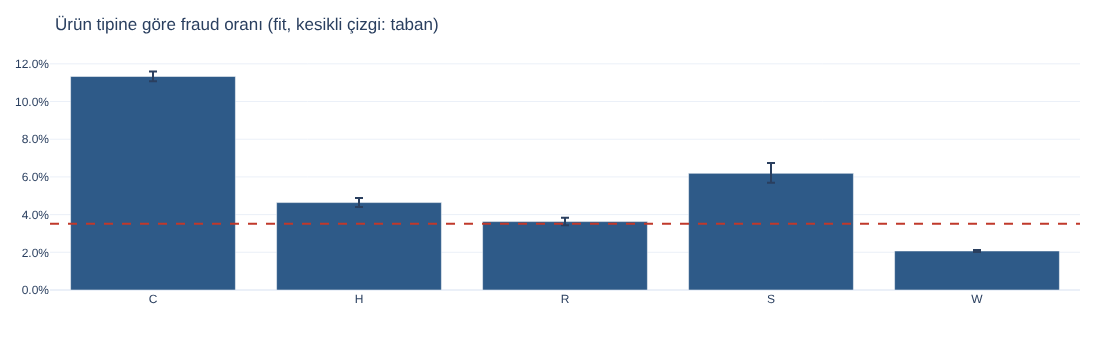

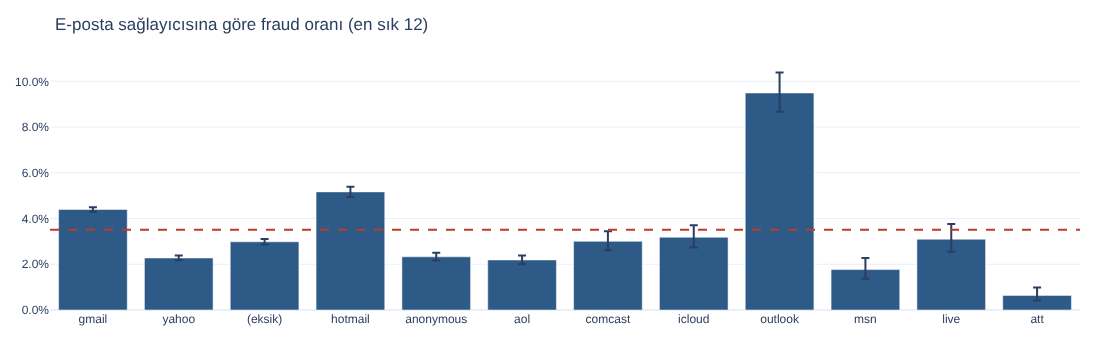

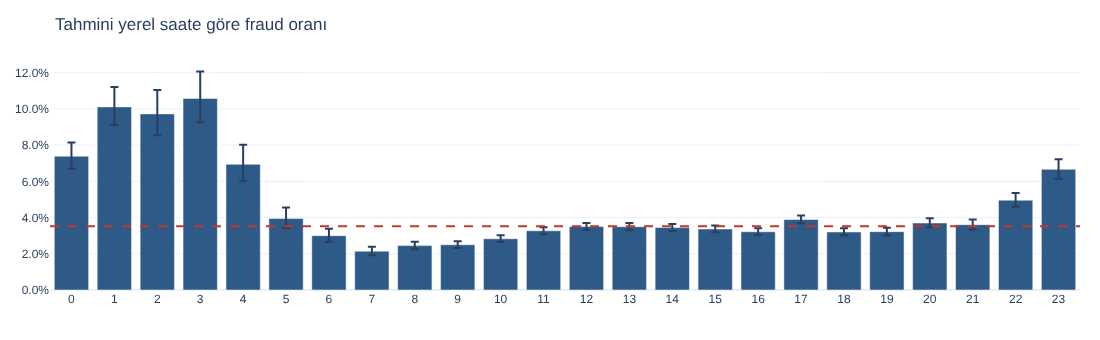

In [34]:
F = df.loc[fit]
yF = y.loc[fit]
BASE = float(yF.mean())
note("fit fraud oranı", round(BASE, 4))

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - h, c + h

def rate_table(key, min_n=200, top=None):
    g = pd.DataFrame({"k": key.astype("object").fillna("(eksik)") if not pd.api.types.is_numeric_dtype(key) else key, "y": yF})
    t = g.groupby("k")["y"].agg(n="size", fraud="sum")
    t = t[t["n"] >= min_n]
    if top:
        t = t.sort_values("n", ascending=False).head(top)
    t["oran"] = t["fraud"] / t["n"]
    lo, hi = wilson(t["fraud"].to_numpy(), t["n"].to_numpy())
    t["alt"], t["üst"], t["lift"] = lo, hi, t["oran"] / BASE
    return t

def rate_fig(t, title):
    fig = go.Figure(go.Bar(x=t.index.astype(str), y=t["oran"], marker_color=C_MAIN,
                           error_y=dict(type="data", symmetric=False, array=t["üst"] - t["oran"], arrayminus=t["oran"] - t["alt"])))
    fig.add_hline(y=BASE, line_dash="dash", line_color=C_RISK)
    fig.update_layout(title=title, yaxis_tickformat=".1%")
    return fig

for c in ["ProductCD", "card4", "card6", "DeviceType", "has_identity", "addr2_country", "M4"]:
    t = rate_table(F[c])
    print(c); display(t.round(4))
show(rate_fig(rate_table(F["ProductCD"]), "Ürün tipine göre fraud oranı (fit, kesikli çizgi: taban)"), 340)
show(rate_fig(rate_table(F["P_provider"], top=12), "E-posta sağlayıcısına göre fraud oranı (en sık 12)"), 360)
t = rate_table(F["local_hour_est"], min_n=1).sort_index()
show(rate_fig(t, "Tahmini yerel saate göre fraud oranı"), 340)

In [35]:
def binned_lift(s, q=10):
    s = s.astype("float64").replace([np.inf, -np.inf], np.nan)
    b = pd.qcut(s, q, labels=False, duplicates="drop")   # aynı değerler aynı dilimde kalır
    t = pd.DataFrame({"b": b, "x": s, "y": yF}).dropna(subset=["b"]).groupby("b").agg(alt_sınır=("x", "min"), üst_sınır=("x", "max"), n=("y", "size"), oran=("y", "mean"))
    t["lift"] = t["oran"] / BASE
    return t

for c in ["TransactionAmt", "amt_to_ent_avg", "ent_txn_count", "card_age_days", "secs_since_prev", "amt_freq"]:
    print(c); display(binned_lift(F[c]).round(4))
for c, bins in [("vel_1h", [-1, 0, 1, 2, 4, 9, 1e9])]:
    t = rate_table(pd.cut(F[c], bins).astype(str), min_n=50)
    print(c); display(t.round(4))

TransactionAmt


,alt_sınır,üst_sınır,n,oran,lift
b,,,,,
0,0.2510,25.9500,48235,0.0542,1.5412
1,25.9600,35.9500,48945,0.0323,0.9205
2,35.9600,49.0000,51520,0.0324,0.9220
3,49.0010,57.9500,48703,0.0196,0.5587
4,57.9510,68.9500,39585,0.0281,0.7995
5,68.9700,100.0000,59222,0.0364,1.0366
6,100.0100,117.0000,55798,0.0192,0.5473
7,117.0080,159.9500,26190,0.0439,1.2497
8,159.9600,277.0000,46991,0.0392,1.1157


amt_to_ent_avg


,alt_sınır,üst_sınır,n,oran,lift
b,,,,,
0.0000,0.0059,0.2576,43585,0.0258,0.7353
1.0000,0.2576,0.3651,43583,0.0281,0.7993
2.0000,0.3651,0.4705,43584,0.0302,0.8607
3.0000,0.4706,0.5801,43584,0.0281,0.8000
4.0000,0.5801,0.7241,43584,0.0369,1.0494
5.0000,0.7241,0.9003,43583,0.0369,1.0494
6.0000,0.9003,1.0873,43584,0.0366,1.0422
7.0000,1.0873,1.4457,43584,0.0419,1.1911
8.0000,1.4457,2.2222,43597,0.0485,1.3801


ent_txn_count


...

,alt_sınır,üst_sınır,n,oran,lift
b,,,,,
0.0000,0.0000,364.0000,43648,0.0746,2.1231
1.0000,365.0000,"1,689.0000",43535,0.0467,1.3304
2.0000,"1,690.0000","4,876.0000",43577,0.0364,1.0372
3.0000,"4,877.0000","11,981.0000",43577,0.0354,1.0065
4.0000,"11,982.0000","33,046.0000",43583,0.0354,1.0083
5.0000,"33,047.0000","72,298.0000",43583,0.0340,0.9678
6.0000,"72,299.0000","144,884.0000",43584,0.0315,0.8960
7.0000,"144,890.0000","317,190.0000",43584,0.0237,0.6733
8.0000,"317,194.0000","815,531.0000",43584,0.0195,0.5551


amt_freq


,alt_sınır,üst_sınır,n,oran,lift
b,,,,,
0,0.0000,0.0001,48262,0.0593,1.6890
1,0.0001,0.0003,46535,0.0834,2.3743
2,0.0003,0.0013,47351,0.0421,1.1979
3,0.0014,0.0041,47261,0.0244,0.6932
4,0.0043,0.0079,48006,0.0358,1.0203
5,0.0088,0.0127,46659,0.0232,0.6606
6,0.0127,0.0182,51038,0.0239,0.6798
7,0.0193,0.0375,54164,0.0265,0.7535
8,0.0389,0.0395,37051,0.0053,0.1506


vel_1h


,n,fraud,oran,alt,üst,lift
k,,,,,,
"(-1.0, 0.0]",355298,10212,0.0287,0.0282,0.0293,0.8180
"(0.0, 1.0]",68737,3343,0.0486,0.0471,0.0503,1.3842
"(1.0, 2.0]",24161,1398,0.0579,0.0550,0.0609,1.6468
"(2.0, 4.0]",16397,1077,0.0657,0.0620,0.0696,1.8694
"(4.0, 9.0]",6692,455,0.0680,0.0622,0.0743,1.9351
"(9.0, 1000000000.0]",1147,114,0.0994,0.0834,0.1181,2.8288


,kapsama,n,oran,alt,üst,lift
bayrak,,,,,,
nadir kombinasyon,0.0011,516,0.1337,0.1070,0.1658,3.8059
addr2 eksik,0.1138,53761,0.1140,0.1113,0.1167,3.2442
3 ondalıklı tutar,0.1079,50981,0.1133,0.1106,0.1161,3.2257
yabancı ülke,0.0083,3931,0.1038,0.0946,0.1137,2.9540
düşük hacim penceresi (gece vekili),0.0407,19232,0.0753,0.0717,0.0792,2.1444
1 saatte >=3 önceki işlem,0.0513,24236,0.0679,0.0648,0.0712,1.9330
entity için yeni cihaz,0.0480,22677,0.0669,0.0637,0.0702,1.9027
ürün içi tutar outlier'ı,0.0232,10959,0.0503,0.0463,0.0545,1.4310
yeni kart (D1=0),0.4895,231279,0.0413,0.0405,0.0421,1.1756


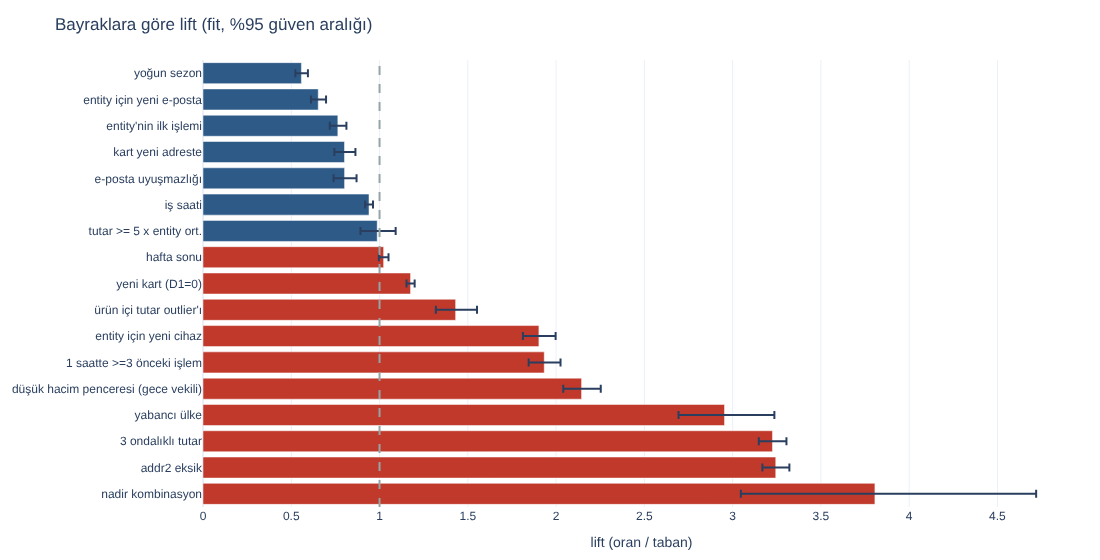

In [36]:
flags = {
    "düşük hacim penceresi (gece vekili)": F["is_low_volume_window"],
    "iş saati": F["is_business_hours"], "hafta sonu": F["is_weekend"], "yoğun sezon": F["holiday_season"],
    "yabancı ülke": F["foreign_addr2"], "addr2 eksik": F["addr2_missing"], "3 ondalıklı tutar": F["amt_decimals"] == 3,
    "yeni kart (D1=0)": F["is_new_card"], "e-posta uyuşmazlığı": F["email_mismatch"],
    "kart yeni adreste": F["card_new_addr"], "entity için yeni cihaz": F["new_device_for_entity"],
    "entity için yeni e-posta": F["new_email_for_entity"], "nadir kombinasyon": F["rare_combo"],
    "ürün içi tutar outlier'ı": F["amt_outlier_in_product"], "1 saatte >=3 önceki işlem": F["vel_1h"] >= 3,
    "entity'nin ilk işlemi": F["ent_txn_count"] == 0, "tutar >= 5 x entity ort.": F["amt_to_ent_avg"] >= 5,
}
rows = []
for name, m in flags.items():
    m = m.fillna(False).astype(bool); k, n = int(yF[m].sum()), int(m.sum())
    if n == 0:
        continue
    lo, hi = wilson(k, n)
    rows.append({"bayrak": name, "kapsama": n / len(F), "n": n, "oran": k / n, "alt": lo, "üst": hi, "lift": k / n / BASE})
flag_t = pd.DataFrame(rows).set_index("bayrak").sort_values("lift", ascending=False)
display(flag_t.round(4))
fig = go.Figure(go.Bar(x=flag_t["lift"], y=flag_t.index, orientation="h", marker_color=[C_RISK if v > 1 else C_MAIN for v in flag_t["lift"]],
                       error_x=dict(type="data", symmetric=False, array=flag_t["üst"] / BASE - flag_t["lift"], arrayminus=flag_t["lift"] - flag_t["alt"] / BASE)))
fig.add_vline(x=1, line_dash="dash", line_color=C_MUTED)
fig.update_layout(title="Bayraklara göre lift (fit, %95 güven aralığı)", xaxis_title="lift (oran / taban)")
show(fig, 560)

,C,H,R,S,W
düşük hacim penceresi (gece vekili),2.3800,2.9100,2.3400,1.6000,1.6200
iş saati,0.8500,0.9200,0.6900,0.7900,1.0900
hafta sonu,1.0900,0.9400,1.4100,1.1000,0.9500
yoğun sezon,0.5300,0.3000,0.0700,0.4300,0.8300
yabancı ülke,0.7700,4.4400,4.0600,NaN,NaN
addr2 eksik,1.3200,NaN,NaN,NaN,NaN
3 ondalıklı tutar,1.0000,NaN,NaN,NaN,NaN
yeni kart (D1=0),0.9500,0.5500,2.3500,0.5700,0.8200
e-posta uyuşmazlığı,NaN,0.6200,0.6100,NaN,NaN
kart yeni adreste,0.7700,1.0600,0.8600,0.3000,0.7300


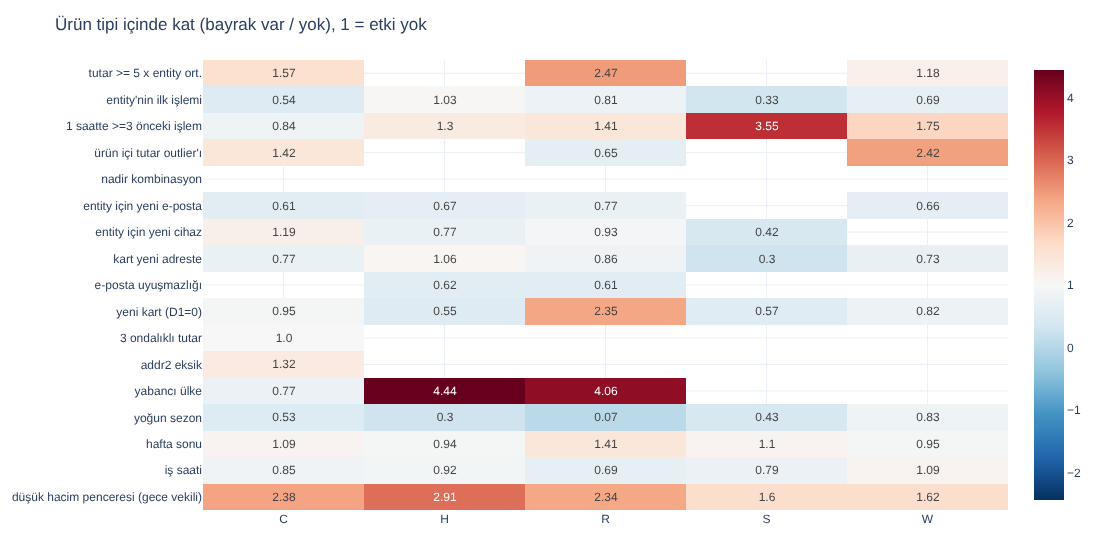

In [37]:
# Ürün tipi içinde lift: etki ürün içinde de sürüyor mu?
within = {}
for name, m in flags.items():
    m = m.fillna(False).astype(bool); row = {}
    for p, idx in F.groupby("ProductCD", observed=True).groups.items():
        mm, yy = m.loc[idx], yF.loc[idx]
        if mm.sum() >= 200 and (~mm).sum() >= 200 and yy[~mm].mean() > 0:
            row[str(p)] = yy[mm].mean() / yy[~mm].mean()
    within[name] = row
within = pd.DataFrame(within).T
display(within.round(2))
txt = np.where(np.isnan(within.values.astype(float)), "", np.round(within.values.astype(float), 2).astype(str))
fig = go.Figure(go.Heatmap(z=within.values, x=within.columns, y=within.index, colorscale="RdBu_r", zmid=1,
                           text=txt, texttemplate="%{text}"))
fig.update_layout(title="Ürün tipi içinde kat (bayrak var / yok), 1 = etki yok")
show(fig, 560)

## 18. Context ve kural adayları (yalnızca fit)

**Context:** hangi bağlamlarda fraud oranı tabanın altında? Bu segmentlerde anomali skorunu yumuşatmak false positive'i azaltabilir. Güvenilir entity vekili: geçmişi uzun (fit'te önceki işlem sayısı q90 üstü), kart yaşı ≥ 30 gün, tutarı kendi ortalamasına yakın (|z| ≤ 2), cihazı ve e-postası yeni değil.

**Kural adayları:** kapsama (kaç işlem) ve lift. Buradaki numaralar (K1, K2…) yalnızca bu notebook'a ait; projedeki kural ID'leri `configs/rules.yaml`'dadır.

In [38]:
q90 = float(F["ent_txn_count"].quantile(0.90))
trusted = ((F["ent_txn_count"] >= q90) & (F["card_age_days"] >= 30) & (F["ent_amt_z"].abs() <= 2)
           & ~F["new_device_for_entity"] & ~F["new_email_for_entity"])
ctx = {"iş saati": F["is_business_hours"], "hafta sonu": F["is_weekend"], "yoğun sezon": F["holiday_season"],
       "güvenilir entity (vekil)": trusted, "uzun geçmiş (önceki işlem >= q90)": F["ent_txn_count"] >= q90,
       "kart yaşı >= 30 gün": F["card_age_days"] >= 30, "tutar entity ortalamasına yakın (|z| <= 2)": F["ent_amt_z"].abs() <= 2}
rows = []
for name, m in ctx.items():
    m = m.fillna(False).astype(bool); n = int(m.sum())
    rows.append({"context": name, "kapsama": n / len(F), "oran": yF[m].mean() if n else np.nan, "lift": yF[m].mean() / BASE if n else np.nan})
ctx_t = pd.DataFrame(rows).set_index("context")
display(ctx_t.round(4))
note("güvenilir entity vekili kapsama / lift", f"{ctx_t.loc['güvenilir entity (vekil)', 'kapsama']:.4f} / {ctx_t.loc['güvenilir entity (vekil)', 'lift']:.2f}")
note("q90 önceki işlem eşiği", q90)

,kapsama,oran,lift
context,,,
iş saati,0.4223,0.0330,0.9404
hafta sonu,0.3069,0.0359,1.0231
yoğun sezon,0.0996,0.0196,0.5575
güvenilir entity (vekil),0.0363,0.0246,0.6990
uzun geçmiş (önceki işlem >= q90),0.1001,0.0455,1.2946
kart yaşı >= 30 gün,0.3847,0.0176,0.5016
tutar entity ortalamasına yakın (|z| <= 2),0.7950,0.0361,1.0261


güvenilir entity vekili kapsama / lift: 0.0363 / 0.70
q90 önceki işlem eşiği: 809.0


yüksek tutar eşiği (fit q95): 441.95


,tetikleme,kapsama,oran,alt,üst,lift,yakalanan fraud payı
aday,,,,,,,
K1 yüksek tutar + yabancı ülke + gece,1,0.0000,1.0000,0.2065,1.0000,28.4615,0.0001
K2 yüksek tutar + yabancı ülke,54,0.0001,0.2407,0.1464,0.3695,6.8518,0.0008
K6 yeni cihaz + yüksek tutar,282,0.0006,0.1596,0.1214,0.2069,4.5417,0.0027
K3 yüksek tutar + gece,745,0.0016,0.1490,0.1252,0.1764,4.2406,0.0067
K10 hafta sonu + gece + yüksek tutar,278,0.0006,0.1439,0.1075,0.1900,4.0952,0.0024
"K4 card testing (küçük tutar, 1 saatte >=2 önceki küçük)",4854,0.0103,0.1036,0.0954,0.1125,2.9493,0.0303
K5 velocity (1 saatte >=5 önceki işlem),7839,0.0166,0.0726,0.0670,0.0785,2.0659,0.0343
K7 e-posta uyuşmazlığı + yüksek tutar,472,0.0010,0.0530,0.0361,0.0770,1.5075,0.0015
K13 yeni kart + yüksek tutar,14849,0.0314,0.0438,0.0406,0.0472,1.2459,0.0392


Grafiğe alınmayan (<30 tetikleme): K1 yüksek tutar + yabancı ülke + gece, K11 identity yok + yüksek tutar (W hariç), K12 nadir kombinasyon + yüksek tutar


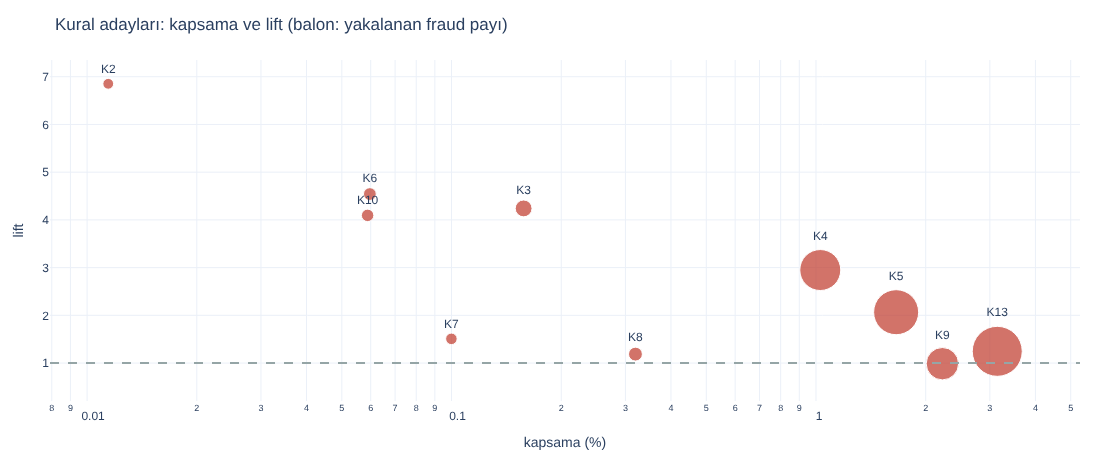

In [39]:
small = F["TransactionAmt"] <= F["TransactionAmt"].quantile(0.10)
high = F["TransactionAmt"] >= F["TransactionAmt"].quantile(0.95)
ec_f = F["entity"].astype("category").cat.codes.to_numpy()
small_prev_1h = pd.Series(window_sum(ec_f, F["TransactionDT"].to_numpy(), 3600, small.to_numpy()), index=F.index)
note("yüksek tutar eşiği (fit q95)", round(float(F["TransactionAmt"].quantile(0.95)), 2))

cands = {
    "K1 yüksek tutar + yabancı ülke + gece": high & F["foreign_addr2"] & F["is_low_volume_window"],
    "K2 yüksek tutar + yabancı ülke": high & F["foreign_addr2"],
    "K3 yüksek tutar + gece": high & F["is_low_volume_window"],
    "K4 card testing (küçük tutar, 1 saatte >=2 önceki küçük)": small & (small_prev_1h >= 2),
    "K5 velocity (1 saatte >=5 önceki işlem)": F["vel_1h"] >= 5,
    "K6 yeni cihaz + yüksek tutar": F["new_device_for_entity"] & high,
    "K7 e-posta uyuşmazlığı + yüksek tutar": F["email_mismatch"] & high,
    "K8 kart yeni adreste + yüksek tutar": F["card_new_addr"] & high,
    "K9 tutar >= 5 x entity ort.": F["amt_to_ent_avg"] >= 5,
    "K10 hafta sonu + gece + yüksek tutar": F["is_weekend"] & F["is_low_volume_window"] & high,
    "K11 identity yok + yüksek tutar (W hariç)": ~F["has_identity"] & high & (F["ProductCD"] != "W"),
    "K12 nadir kombinasyon + yüksek tutar": F["rare_combo"] & high,
    "K13 yeni kart + yüksek tutar": F["is_new_card"] & high,
}
rows = []
for name, m in cands.items():
    m = m.fillna(False).astype(bool); k, n = int(yF[m].sum()), int(m.sum())
    lo, hi = wilson(k, n) if n else (np.nan, np.nan)
    rows.append({"aday": name, "tetikleme": n, "kapsama": n / len(F), "oran": k / n if n else np.nan, "alt": lo, "üst": hi,
                 "lift": k / n / BASE if n else np.nan, "yakalanan fraud payı": k / yF.sum()})
rules_t = pd.DataFrame(rows).set_index("aday").sort_values("lift", ascending=False)
display(rules_t.round(4))
r = rules_t[rules_t["tetikleme"] >= 30]      # çok az tetiklenen adayların lift'i güvenilmez, grafiğe alınmaz
print("Grafiğe alınmayan (<30 tetikleme):", ", ".join(rules_t.index[rules_t["tetikleme"] < 30]))
fig = go.Figure(go.Scatter(x=r["kapsama"] * 100, y=r["lift"], mode="markers+text", text=[s.split(" ")[0] for s in r.index],
                           textposition="top center", marker=dict(size=10 + 40 * r["yakalanan fraud payı"] / max(r["yakalanan fraud payı"].max(), 1e-9), color=C_RISK)))
fig.add_hline(y=1, line_dash="dash", line_color=C_MUTED)
fig.update_layout(title="Kural adayları: kapsama ve lift (balon: yakalanan fraud payı)", xaxis_title="kapsama (%)", xaxis_type="log", yaxis_title="lift")
show(fig, 460)

## 19. Sayısal özet

Notebook boyunca kaydedilen anahtar sayılar tek tabloda.

In [40]:
display(pd.Series(SUMMARY, name="değer").astype(str).to_frame())
print(f"Toplam çalışma süresi: {(time.time() - T_START) / 60:.1f} dk")

,değer
satır,590540
kolon (birleşik),435
identity payı,0.2442
datetime_offset kolonları,TransactionDT
quasi_constant kolon sayısı,24
tekrarlı satır,3
birebir aynı kolon,0
eksiklik bloğu sayısı,69
train-test arası boşluk (gün),30.0
train ve test tepeleri arası gün,367


Toplam çalışma süresi: 2.7 dk
